# Final project model: joint MiniLM trained on UPenn + Stanford

This is the **final selected prototype** documented in the official report. It trains on the two real datasets only, with equal aggregate source loss weight, separate calibration and validation, and two seeds. Seed 42 is the fixed inference export.

The three-dataset variants remain in the separate comparison notebook. In the historical Mac runs they improved templated synthetic scenarios but lost real-test F1 on both datasets and scored 13/16 extra binary draft probes versus 14/16 for this control. The subsequently supplied Kaggle run scored 12/16. These are separate measured runs. This does not prove universal accuracy: the older Stanford blend has higher Stanford benchmark F1.

Enable **Internet ON and GPU T4 ×2**, then Run All. One T4 is used. No dataset upload or API key is required. The three dataset folders are generated, but CustomForum is **diagnostic only** and its draft labels never update this model. Historical test results and assistant-authored context probes are exploratory.


## What was already tested and why it was not selected

Read this section before proposing another experiment. These are **previously measured results**, not models retrained by Run All in this notebook. F1 refers to the urgent class. A method not being selected does not mean it never works. All causal explanations remain hypotheses unless isolated by an experiment.

| Previous method | Where measured | UPenn F1 / Stanford F1 | Finding and decision |
|---|---|---|---|
| TF-IDF + Logistic Regression | Earlier user-supplied Kaggle log | 0.5781 / 0.7215 | Useful baseline; lower same-source F1 than source-specific fine-tuned MiniLM in that earlier Kaggle run. This does not establish that it loses on every future post. |
| TF-IDF + linear SVM | Earlier user-supplied Kaggle log | 0.5289 / 0.7185 | Already trained and evaluated. Lower same-source F1 in that run; SVM is an alternative classifier, not an automatic extra layer of contextual understanding. |
| TF-IDF + Naive Bayes | Earlier user-supplied Kaggle log | 0.3919 / 0.6453 | Already tested; lower same-source F1 in that run. It remains part of the comparison evidence. |
| Frozen MiniLM embeddings + LR | Earlier user-supplied Kaggle log | 0.5395 / 0.6210 | Already tested; keeping the encoder frozen did not match the source-specific fine-tuned classifier in that run. |
| Source-specific MiniLM fine-tuning | Historical Mac runs | 0.6222 / 0.8036 | Successful reference method. Separate models per source; different fit pools, checkpoint selection and score policies from this joint model. |
| MiniLM plus TF-IDF blend | Historical Mac runs | 0.6364 / 0.8092 | Improved same-source benchmark F1 and remains the highest measured Stanford F1 here. It did not improve every transfer direction; the selected joint prototype is not universally best. |
| Larger DeBERTa, fixed calibrated threshold 0.5 | Historical Mac diagnostic | 0.6119 / 0.7964 | Mixed policy had lower F1 with higher Recall. Threshold, calibration, fit pools and tuning budget also differ; these runs do not prove a larger architecture is inherently inferior. |
| Joint MiniLM on two real sources | Historical Mac, seed 42 | 0.6667 / 0.7742 | Chosen shared prototype; improved UPenn relative to the older source model, but lost Stanford Recall/F1. The improvement on 16 draft probes is small and not independent deployment evidence. |
| Joint MiniLM plus synthetic CE and pairwise loss | Historical Mac, seed 42 | 0.6612 / 0.7607 | Lower real-test F1 than the matched two-source control on both sources and both seeds. Synthetic challenge 24/24 did not generalize consistently to new phrasing; 13/16 extra draft probes versus control 14/16. |

**Augmentation was tested, with mixed outcomes.** The older source-only experiment expanded contractions and tested plain, weighted and weighted-plus-augmentation scouts. UPenn weighted-plus-augmentation validation F1 was 0.5263, versus 0.4878 for weighting alone; it was selected. Stanford plain was 0.8021, versus 0.7973 for weighting plus augmentation; plain was selected. The three-source trial was a separate synthetic weak-supervision test. These results do not establish that all possible paraphrase augmentation fails.

**Five-fold CV was already used** by the older source-specific MiniLM pipeline for out-of-fold threshold/epoch selection. This joint notebook instead keeps fit, calibration, validation and test separate and reports two training seeds. Repeating CV does not create additional independent labels.

**AI audit of CustomForum:** all 160 fixed texts were inspected under the current-support rubric; 136 retain binary draft labels, 12 need context and 12 are outside the supported scope. Only 82 binary examples belong to training. All 40 still-blocked updates share one suffix. AI reinspection is not independent human approval and does not turn synthetic scenarios into real student evidence. The earlier authorized synthetic experiment already trained on draft labels; the two-source notebook deliberately excludes them after comparison.

**Subsequent actual Kaggle run, supplied by the user:**

| Seed | UPenn F1 | Stanford F1 |
|---|---:|---:|
| 42 | 0.6613 | 0.7701 |
| 43 | 0.6260 | 0.7605 |

That run completed in about 16.8 minutes, exported 182.7 MB and scored 12/16 extra binary draft probes. Its synthetic challenge F1 was 0.80, accuracy 0.7083, with 0/7 complete three-state groups correct. This demonstrates continuing errors on resolution and quotation. These numbers are historical Kaggle references; fresh outputs below may differ. Its Transformers version was 5.20.2, while the local run used 4.57.6. The setup cell checks module presence, so its requested version pin is not enforced for preinstalled packages; keep the printed versions with every run. No single cause of the environment-related differences has been isolated.

**Ten epochs has not been tested in this joint pipeline.** Both supplied Kaggle seeds peaked in mean validation AP at epoch 3 and declined at epoch 4. That does not rule out later improvement. A future ten-epoch cap with early stopping would be a new experiment, retaining the best validation checkpoint rather than automatically exporting epoch 10. This code also bases its learning-rate schedule on the epoch cap, so changing the cap changes optimization before epoch 4 as well. No ten-epoch result or improvement is claimed.

Run All below trains only the selected two-source method (seeds 42 and 43). It does not repeat the older SVM, augmentation, blend, DeBERTa or synthetic-training experiments. The full historical comparison notebook remains a separate optional artifact.


In [1]:
import os,sys,json,subprocess,importlib.util
from pathlib import Path
from IPython.display import display,Image,Markdown
IS_KAGGLE=Path('/kaggle/working').exists()
PROJECT=Path(os.environ.get('FORUM_PROJECT_DIR','/kaggle/working/Project' if IS_KAGGLE else str(Path.cwd()/'Project'))).resolve()
for name in ['scripts','models','reports/final_minilm_trial','reports/figures','.cache/tmp']:(PROJECT/name).mkdir(parents=True,exist_ok=True)
os.environ.update(PROJECT_ROOT=str(PROJECT),HF_HOME=str(PROJECT/'.cache/huggingface'),HF_HUB_CACHE=str(PROJECT/'.cache/huggingface/hub'),
    HF_XET_CACHE=str(PROJECT/'.cache/huggingface/xet'),HF_HUB_DISABLE_XET='1',HF_HUB_DISABLE_TELEMETRY='1',
    MPLCONFIGDIR=str(PROJECT/'.cache/matplotlib'),TMPDIR=str(PROJECT/'.cache/tmp'),PIP_CACHE_DIR=str(PROJECT/'.cache/pip'),
    OMP_NUM_THREADS='1',OPENBLAS_NUM_THREADS='1',MKL_NUM_THREADS='1',TOKENIZERS_PARALLELISM='false',PYTORCH_ENABLE_MPS_FALLBACK='1')
RUN_TRAINING=os.environ.get('FORUM_REUSE_FINAL_TRIAL','0')!='1'
RUN_SYNTHETIC_TRIAL=False
print('Project:',PROJECT,'Mode:','TRAIN' if RUN_TRAINING else 'LOCAL VALIDATION: reuse completed training',
      'Synthetic weak supervision:',RUN_SYNTHETIC_TRIAL)


Project: /Users/nhaterik/lastyear/machine/Project Mode: LOCAL VALIDATION: reuse completed training Synthetic weak supervision: False


In [2]:
required={'torch':'torch>=2.8','transformers':'transformers==4.57.6','sklearn':'scikit-learn>=1.6,<2',
    'numpy':'numpy','matplotlib':'matplotlib','joblib':'joblib','sentencepiece':'sentencepiece==0.2.1'}
missing=[spec for module,spec in required.items() if importlib.util.find_spec(module) is None]
if missing:subprocess.run([sys.executable,'-m','pip','install',*missing],check=True)
import torch,transformers,sklearn,numpy as np
DEVICE='cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
if RUN_TRAINING and IS_KAGGLE and DEVICE!='cuda':raise RuntimeError('Enable a Kaggle GPU before training.')
print({'torch':torch.__version__,'transformers':transformers.__version__,'sklearn':sklearn.__version__,
       'device':DEVICE,'visible_gpus':torch.cuda.device_count(),'training_gpu_count':1 if DEVICE=='cuda' else 0})


/Users/nhaterik/lastyear/machine/Project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'torch': '2.15.0', 'transformers': '4.57.6', 'sklearn': '1.9.1', 'device': 'mps', 'visible_gpus': 0, 'training_gpu_count': 0}


## Embedded source: prepare_data.py

In [3]:
(PROJECT/"scripts"/'prepare_data.py').write_text('"""Download and audit two pinned public datasets using only Python\'s standard library."""\nfrom __future__ import annotations\n\nimport argparse\nimport csv\nimport hashlib\nimport html\nimport json\nimport math\nimport re\nimport subprocess\nimport unicodedata\nfrom collections import Counter, defaultdict\nfrom pathlib import Path\n\nROOT = Path(__file__).resolve().parents[1]\nREVISION = "ebf3695f01d2dec197253eb89499f4835bb7d0fa"\nFILES = {"upenn": "All_Courses_REDACTED_CODED.csv", "stanford": "Stanford.csv"}\nEXPECTED_SHA256 = {\n    "upenn": "403301d079abcea1acc318b7a63f766658350dbc0e85eead79f7befc65aa48c3",\n    "stanford": "31e8885939604a20cd0a903d1e5ebca811b850530b8e9ed5169e1936628142f2",\n}\nFIELDS = ["post_id", "source", "source_row", "source_id", "source_time", "source_course_type", "text_raw",\n          "text_clean", "urgency", "priority", "word_count", "text_sha256"]\nTAG = re.compile(r"</?(?:p|br|div|span|a|b|i|strong|em|ul|ol|li|blockquote|pre|code|hr)(?:\\s[^<>]*?)?\\s*/?>", re.I)\n\n\ndef sha256(path: Path) -> str:\n    return hashlib.sha256(path.read_bytes()).hexdigest()\n\n\ndef dump_json(path: Path, data) -> None:\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(data, ensure_ascii=False, indent=2, sort_keys=True) + "\\n", encoding="utf-8")\n\n\ndef clean_text(text: str) -> str:\n    return " ".join(TAG.sub(" ", unicodedata.normalize("NFC", html.unescape(text))).split())\n\n\ndef percentile(values, fraction):\n    ordered = sorted(values)\n    index = (len(ordered) - 1) * fraction\n    low = math.floor(index)\n    high = math.ceil(index)\n    return round(ordered[low] + (ordered[high] - ordered[low]) * (index - low), 2)\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--download", action="store_true", help="Download missing raw files, never replace existing files")\n    args = parser.parse_args()\n    rejected, datasets, audit = [], {}, {"source_revision": REVISION, "label_rule": "priority = int(urgency > 4)", "datasets": {}}\n    for source, filename in FILES.items():\n        path = ROOT / "data/raw" / filename\n        url = f"https://raw.githubusercontent.com/pcla-code/forum-posts-urgency/{REVISION}/{filename}"\n        path.parent.mkdir(parents=True, exist_ok=True)\n        if not path.exists():\n            if not args.download:\n                raise SystemExit(f"Thiếu {path.name}. Chạy bash Project/run.sh --download từ machine.")\n            print(f"Đang tải {source} từ commit {REVISION[:12]}...", flush=True)\n            temporary = path.with_suffix(".csv.part")\n            try:\n                subprocess.run(["curl", "-q", "--fail", "--location", "--silent", "--show-error",\n                                "--connect-timeout", "10", "--max-time", "120", "--retry", "1",\n                                "--output", str(temporary), url], check=True)\n                temporary.replace(path)\n            finally:\n                temporary.unlink(missing_ok=True)\n        if sha256(path) != EXPECTED_SHA256[source]:\n            raise ValueError(f"SHA-256 tệp gốc không khớp phiên bản cố định: {filename}")\n        groups = defaultdict(list)\n        counts = Counter()\n        with path.open(encoding="utf-8-sig", newline="") as handle:\n            reader = csv.DictReader(handle)\n            if not {"post_text", "Urgency_1_7"}.issubset(reader.fieldnames or []):\n                raise ValueError(f"Schema không phù hợp: {path.name}")\n            columns = reader.fieldnames\n            for row_number, raw in enumerate(reader, start=2):\n                counts["raw_rows"] += 1\n                reason = None\n                if None in raw or raw.get("post_text") is None or raw.get("Urgency_1_7") is None:\n                    reason = "malformed_or_missing_fields"\n                try:\n                    urgency = float(raw.get("Urgency_1_7") or "nan")\n                except (TypeError, ValueError):\n                    urgency = float("nan")\n                if reason is None and (not math.isfinite(urgency) or not 1 <= urgency <= 7):\n                    reason = "missing_or_invalid_urgency"\n                text = clean_text(raw.get("post_text") or "")\n                if reason is None and not text:\n                    reason = "empty_text"\n                if reason:\n                    counts[reason] += 1\n                    rejected.append({"source": source, "source_row": row_number, "reason": reason})\n                    continue\n                counts["valid_rows"] += 1\n                key = hashlib.sha256(text.casefold().encode("utf-8")).hexdigest()\n                groups[key].append({"post_id": f"{source}_{row_number:06d}", "source": source,\n                                    "source_row": row_number, "source_id": raw.get("id", ""),\n                                    "source_time": raw.get("post_time", ""),\n                                    "source_course_type": raw.get("CourseType", ""), "text_raw": raw["post_text"],\n                                    "text_clean": text, "urgency": urgency, "priority": int(urgency > 4),\n                                    "word_count": len(text.split()), "text_sha256": key})\n        retained = []\n        for rows in groups.values():\n            conflict = len({row["priority"] for row in rows}) > 1\n            if conflict:\n                counts["conflicting_groups"] += 1\n            discarded = rows if conflict else rows[1:]\n            reason = "conflicting_binary_labels" if conflict else "duplicate_within_source"\n            counts[reason] += len(discarded)\n            rejected.extend({"source": source, "source_row": row["source_row"], "reason": reason} for row in discarded)\n            if not conflict:\n                retained.append(rows[0])\n        counts["after_within_source_dedup"] = len(retained)\n        counts["cross_source_duplicates"] = 0\n        datasets[source] = sorted(retained, key=lambda row: row["source_row"])\n        audit["datasets"][source] = {"raw_file": str(path.relative_to(ROOT)), "url": url,\n                                       "raw_sha256": sha256(path), "raw_bytes": path.stat().st_size,\n                                       "columns": columns, "counts": dict(counts)}\n\n    upenn_keys = {row["text_sha256"] for row in datasets["upenn"]}\n    unique_stanford = []\n    for row in datasets["stanford"]:\n        if row["text_sha256"] in upenn_keys:\n            audit["datasets"]["stanford"]["counts"]["cross_source_duplicates"] += 1\n            rejected.append({"source": "stanford", "source_row": row["source_row"], "reason": "duplicate_across_sources"})\n        else:\n            unique_stanford.append(row)\n    datasets["stanford"] = unique_stanford\n\n    for source, rows in datasets.items():\n        if not rows:\n            raise ValueError(f"Không có dữ liệu hợp lệ: {source}")\n        target = ROOT / "data/processed" / f"{source}.csv"\n        target.parent.mkdir(parents=True, exist_ok=True)\n        with target.open("w", encoding="utf-8", newline="") as handle:\n            writer = csv.DictWriter(handle, fieldnames=FIELDS)\n            writer.writeheader()\n            writer.writerows(rows)\n        item = audit["datasets"][source]\n        item["counts"]["final_rows"] = len(rows)\n        item["label_counts"] = dict(Counter(str(row["priority"]) for row in rows))\n        item["urgency_counts"] = dict(Counter(str(row["urgency"]) for row in rows))\n        lengths = [row["word_count"] for row in rows]\n        item["word_lengths"] = {"min": min(lengths), "median": percentile(lengths, .5),\n                                 "p95": percentile(lengths, .95), "max": max(lengths),\n                                 "mean": round(sum(lengths) / len(lengths), 2)}\n        bounds = [(0, 25), (25, 50), (50, 100), (100, 200), (200, 400), (400, None)]\n        item["length_histogram"] = {f"{lower + 1}–{upper}" if upper else f">{lower}":\n            sum(length > lower and (upper is None or length <= upper) for length in lengths)\n            for lower, upper in bounds}\n        item["processed_file"] = str(target.relative_to(ROOT))\n        item["processed_sha256"] = sha256(target)\n        n_rejected = sum(record["source"] == source for record in rejected)\n        assert item["counts"]["raw_rows"] == len(rows) + n_rejected\n        assert all(row["text_clean"].strip() for row in rows)\n        assert all(math.isfinite(row["urgency"]) and 1 <= row["urgency"] <= 7 for row in rows)\n        assert all(row["priority"] == int(row["urgency"] > 4) for row in rows)\n        assert len({row["text_sha256"] for row in rows}) == len(rows)\n        assert {row["priority"] for row in rows} == {0, 1}\n        print(f"{source}: raw={item[\'counts\'][\'raw_rows\']}, final={len(rows)}, priority={item[\'label_counts\'].get(\'1\', 0)}", flush=True)\n    assert not ({row["text_sha256"] for row in datasets["upenn"]} &\n                {row["text_sha256"] for row in datasets["stanford"]})\n    audit["checks"] = {"rows_accounted_for": True, "nonempty_text": True, "labels_in_range": True,\n                        "both_binary_classes_present": True, "no_exact_duplicates_within_sources": True,\n                        "no_exact_duplicates_between_sources": True}\n    dump_json(ROOT / "reports/data_audit.json", audit)\n    with (ROOT / "reports/rejected_rows.csv").open("w", encoding="utf-8", newline="") as handle:\n        writer = csv.DictWriter(handle, fieldnames=["source", "source_row", "reason"])\n        writer.writeheader()\n        writer.writerows(sorted(rejected, key=lambda row: (row["source"], row["source_row"])))\n\n\nif __name__ == "__main__":\n    main()\n',encoding="utf-8")


9552

## Embedded source: train.py

In [4]:
(PROJECT/"scripts"/'train.py').write_text('"""Reproducible source-only model selection and two-source held-out evaluation."""\nfrom __future__ import annotations\nimport csv\nimport hashlib\nimport json\nimport platform\nimport sys\nimport time\nfrom pathlib import Path\nimport joblib\nimport numpy as np\nimport sklearn\nfrom sklearn.base import clone\nfrom sklearn.dummy import DummyClassifier\nfrom sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,\n    f1_score, precision_score, recall_score, roc_auc_score, precision_recall_curve)\nfrom sklearn.model_selection import (GroupShuffleSplit, StratifiedKFold, StratifiedGroupKFold,\n    train_test_split, GridSearchCV, cross_val_predict)\nfrom sklearn.naive_bayes import MultinomialNB\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.svm import LinearSVC\nfrom prepare_data import dump_json, sha256\n\nROOT=Path(__file__).resolve().parents[1]\nOUT=ROOT/\'reports/experiments\'\nSEED=42\nENCODER=\'sentence-transformers/all-MiniLM-L6-v2\'\nENCODER_REV=\'1110a243fdf4706b3f48f1d95db1a4f5529b4d41\'\n\ndef read_csv(path):\n    with path.open(encoding=\'utf-8\',newline=\'\') as f:\n        return list(csv.DictReader(f))\n\ndef write_csv(path, rows):\n    path.parent.mkdir(parents=True,exist_ok=True)\n    with path.open(\'w\',encoding=\'utf-8\',newline=\'\') as f:\n        writer=csv.DictWriter(f,fieldnames=list(rows[0]))\n        writer.writeheader();writer.writerows(rows)\n\ndef scores(model,x):\n    if hasattr(model,\'predict_proba\'):\n        return model.predict_proba(x)[:,1]\n    return model.decision_function(x)\n\ndef metrics(y,s,t,ids):\n    p=np.asarray(s)>=t\n    matrix=confusion_matrix(y,p,labels=[0,1])\n    order=np.lexsort((np.asarray(ids),-np.asarray(s)))\n    k=min(20,len(y));found=int(np.asarray(y)[order[:k]].sum())\n    return dict(precision=float(precision_score(y,p,zero_division=0)),recall=float(recall_score(y,p,zero_division=0)),\n        f1=float(f1_score(y,p,zero_division=0)),macro_f1=float(f1_score(y,p,average=\'macro\')),\n        accuracy=float(accuracy_score(y,p)),average_precision=float(average_precision_score(y,s)),\n        roc_auc=float(roc_auc_score(y,s)),precision_at_20=found/k,recall_at_20=found/int(np.sum(y)),\n        top20_found=found,confusion_matrix=matrix.tolist(),test_size=len(y),positive_count=int(np.sum(y)))\n\ndef tune_threshold(y,s):\n    precision,recall,thresholds=precision_recall_curve(y,s)\n    f=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)\n    # Highest threshold among exact F1 ties; no target test labels are used.\n    index=np.flatnonzero(np.isclose(f,np.max(f),atol=1e-12,rtol=0))[-1]\n    return float(thresholds[index]),float(f[index])\n\ndef embeddings(data):\n    import torch\n    from sentence_transformers import SentenceTransformer\n    from huggingface_hub import snapshot_download\n    snapshot=snapshot_download(ENCODER,revision=ENCODER_REV,\n        allow_patterns=[\'*.json\',\'*.txt\',\'*.safetensors\',\'1_Pooling/*\'])\n    device=\'cuda\' if torch.cuda.is_available() else (\'mps\' if torch.backends.mps.is_available() else \'cpu\')\n    torch.manual_seed(SEED)\n    encoder=SentenceTransformer(snapshot,device=device)\n    result={};info={\'model\':ENCODER,\'revision\':ENCODER_REV,\'device\':device,\n        \'snapshot\':str(Path(snapshot).relative_to(ROOT)),\'max_seq_length\':encoder.max_seq_length,\n        \'dimension\':(encoder.get_embedding_dimension() if hasattr(encoder,\'get_embedding_dimension\')\n                     else encoder.get_sentence_embedding_dimension()),\'sources\':{}}\n    for source,rows in data.items():\n        path=ROOT/\'.cache/embeddings\'/f\'{source}.npz\';path.parent.mkdir(parents=True,exist_ok=True)\n        fingerprint=sha256(ROOT/f\'data/processed/{source}.csv\')\n        if path.exists():\n            cached=np.load(path)\n            if str(cached[\'fingerprint\'])==fingerprint and str(cached[\'revision\'])==ENCODER_REV:\n                result[source]=cached[\'vectors\'];info[\'sources\'][source]={\'cache_used\':True};continue\n        texts=[row[\'text_clean\'] for row in rows]\n        start=time.perf_counter()\n        lengths=[]\n        for i in range(0,len(texts),128):\n            batch=encoder.tokenizer(texts[i:i+128],truncation=False,add_special_tokens=True)[\'input_ids\']\n            lengths.extend(map(len,batch))\n        vectors=encoder.encode(texts,batch_size=64,normalize_embeddings=True,show_progress_bar=True).astype(np.float32)\n        elapsed=time.perf_counter()-start\n        np.savez_compressed(path,vectors=vectors,fingerprint=fingerprint,revision=ENCODER_REV)\n        result[source]=vectors\n        info[\'sources\'][source]={\'cache_used\':False,\'encoding_seconds\':elapsed,\n            \'truncated_posts\':sum(n>encoder.max_seq_length for n in lengths),\'total\':len(texts),\n            \'tokens_p95\':float(np.percentile(lengths,95)),\'tokens_max\':max(lengths)}\n        dump_json(OUT/\'encoder_info.json\',info)\n    # Preserve original measured token/encoding stats when embeddings are reused.\n    if (OUT/\'encoder_info.json\').exists():\n        previous=json.loads((OUT/\'encoder_info.json\').read_text())\n        for source,entry in info[\'sources\'].items():\n            if entry.get(\'cache_used\') and source in previous.get(\'sources\',{}):\n                info[\'sources\'][source]=previous[\'sources\'][source]\n    dump_json(OUT/\'encoder_info.json\',info)\n    return result,info\n\ndef main():\n    OUT.mkdir(parents=True,exist_ok=True)\n    (ROOT/\'models\').mkdir(exist_ok=True)\n    data={source:read_csv(ROOT/f\'data/processed/{source}.csv\') for source in [\'upenn\',\'stanford\']}\n    splits={};folds={};split_rows=[];split_info={}\n    for source,rows in data.items():\n        y=np.array([int(row[\'priority\']) for row in rows]);indices=np.arange(len(rows))\n        if source==\'upenn\':\n            groups=np.array([row[\'source_id\'] for row in rows])\n            assert all(groups)\n            train,test=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(indices,y,groups))\n            folds[source]=list(StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,y[train],groups[train]))\n            assert not (set(groups[train]) & set(groups[test]))\n            policy=\'GroupShuffleSplit by UPenn student id; 3-fold StratifiedGroupKFold for tuning\'\n        else:\n            train,test=train_test_split(indices,test_size=.2,random_state=SEED,stratify=y)\n            folds[source]=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,y[train]))\n            policy=\'Stratified hold-out and 3-fold StratifiedKFold; author/thread IDs unavailable\'\n        for a,b in folds[source]:\n            assert len(set(y[train[a]]))==2 and len(set(y[train[b]]))==2\n        splits[source]=(train,test)\n        split_info[source]={\'policy\':policy,\'train\':len(train),\'test\':len(test),\n            \'train_positives\':int(y[train].sum()),\'test_positives\':int(y[test].sum()),\n            \'processed_sha256\':sha256(ROOT/f\'data/processed/{source}.csv\')}\n        train_set=set(train)\n        assignments={int(i):(\'train\' if i in train_set else \'test\') for i in indices}\n        split_rows.extend({\'source\':source,\'post_id\':row[\'post_id\'],\'split\':assignments[i]} for i,row in enumerate(rows))\n    write_csv(OUT/\'split_ids.csv\',split_rows);dump_json(OUT/\'split_info.json\',split_info)\n    dump_json(OUT/\'config.json\',{\'seed\':SEED,\'folds\':3,\'test_fraction\':.2,\'tfidf\':{\n        \'ngram_range\':[1,2],\'min_df\':2,\'max_df\':.98,\'max_features\':40000,\'sublinear_tf\':True},\n        \'threshold_rule\':\'Maximize positive F1 on source-only out-of-fold predictions; ties use largest threshold\',\n        \'deployment_rule\':\'Best tuned OOF F1 among Stanford-trained models; independent test scores not used\',\n        \'encoder_revision\':ENCODER_REV,\'data_hashes\':{s:i[\'processed_sha256\'] for s,i in split_info.items()}})\n    results=[];cv_records=[]\n    # Train TF-IDF first, so useful artifacts exist before downloading the optional encoder.\n    embedded=None;encoder_info=None\n    for representation in [\'tfidf\',\'minilm\']:\n        if representation==\'minilm\':\n            embedded,encoder_info=embeddings(data)\n        for source,rows in data.items():\n            train,_=splits[source]\n            y=np.array([int(row[\'priority\']) for row in rows]);texts=np.array([row[\'text_clean\'] for row in rows],dtype=object)\n            x=texts if representation==\'tfidf\' else embedded[source]\n            if representation==\'tfidf\':\n                candidates=[(\'logreg\',LogisticRegression(class_weight=\'balanced\',solver=\'liblinear\',max_iter=2000,random_state=SEED),{\'classifier__C\':[.3,1.,3.]}),\n                    (\'svm\',LinearSVC(class_weight=\'balanced\',max_iter=10000,random_state=SEED),{\'classifier__C\':[.3,1.,3.]}),\n                    (\'nb\',MultinomialNB(),{\'classifier__alpha\':[.1,.5,1.]}),\n                    (\'dummy\',DummyClassifier(strategy=\'prior\'),{})]\n            else:\n                candidates=[(\'logreg\',LogisticRegression(class_weight=\'balanced\',solver=\'liblinear\',max_iter=2000,random_state=SEED),{\'C\':[.3,1.,3.,10.]})]\n            for name,classifier,grid in candidates:\n                slug=f\'{representation}_{name}\'\n                print(f\'TRAIN {source} / {slug}\',flush=True)\n                if representation==\'tfidf\':\n                    model=Pipeline([(\'tfidf\',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.98,max_features=40000,\n                        sublinear_tf=True,strip_accents=\'unicode\',dtype=np.float32)),(\'classifier\',classifier)])\n                else:model=classifier\n                start=time.perf_counter()\n                search=GridSearchCV(model,grid,cv=folds[source],scoring=\'f1\',n_jobs=1,refit=True,return_train_score=False)\n                search.fit(x[train],y[train]);model=search.best_estimator_\n                method=\'decision_function\' if name==\'svm\' else \'predict_proba\'\n                oof=cross_val_predict(clone(model),x[train],y[train],cv=folds[source],method=method,n_jobs=1)\n                oof=oof if name==\'svm\' else oof[:,1]\n                default=0. if name==\'svm\' else .5\n                threshold,oof_f1=tune_threshold(y[train],oof)\n                if name==\'dummy\': threshold=default;oof_f1=float(f1_score(y[train],oof>=threshold,zero_division=0))\n                elapsed=time.perf_counter()-start\n                card={\'source\':source,\'model\':slug,\'representation\':representation,\'name\':name,\n                    \'threshold\':threshold,\'default_threshold\':default,\'cv_mean_f1\':float(search.best_score_),\n                    \'cv_std_f1\':float(search.cv_results_[\'std_test_score\'][search.best_index_]),\n                    \'oof_tuned_f1\':oof_f1,\'best_params\':search.best_params_,\'training_seconds\':elapsed}\n                if representation==\'minilm\':card[\'encoder\']=encoder_info\n                cv_records.append(card)\n                bundle={\'model\':model,\'card\':card}\n                joblib.dump(bundle,ROOT/\'models\'/f\'{source}__{slug}.joblib\',compress=3)\n                write_csv(OUT/f\'oof_{source}_{slug}.csv\',[{\'post_id\':rows[i][\'post_id\'],\'label\':int(y[i]),\'score\':float(s)} for i,s in zip(train,oof)])\n                for target,target_rows in data.items():\n                    _,test=splits[target]\n                    test_x=np.array([row[\'text_clean\'] for row in target_rows],dtype=object)[test] if representation==\'tfidf\' else embedded[target][test]\n                    test_y=np.array([int(row[\'priority\']) for row in target_rows])[test]\n                    ids=[target_rows[i][\'post_id\'] for i in test]\n                    start=time.perf_counter();s=scores(model,test_x);infer_seconds=time.perf_counter()-start\n                    record={\'train_source\':source,\'test_source\':target,\'model\':slug,\'threshold\':threshold,\n                        \'training_seconds\':elapsed,\'inference_seconds\':infer_seconds,**metrics(test_y,s,threshold,ids)}\n                    record[\'default_threshold_metrics\']=metrics(test_y,s,default,ids)\n                    results.append(record)\n                    prediction_rows=[]\n                    for i,label,score in zip(test,test_y,s):\n                        row=target_rows[i];pred=int(score>=threshold)\n                        prediction_rows.append({\'post_id\':row[\'post_id\'],\'source\':target,\'source_id\':row[\'source_id\'],\n                            \'course_type\':row[\'source_course_type\'],\'text\':row[\'text_clean\'],\'urgency\':row[\'urgency\'],\n                            \'label\':int(label),\'predicted\':pred,\'score\':float(score),\n                            \'error\':\'FN\' if label==1 and pred==0 else \'FP\' if label==0 and pred==1 else \'\'})\n                    write_csv(OUT/f\'predictions_{source}_{target}_{slug}.csv\',prediction_rows)\n                    print(f\'  TEST {target}: P={record["precision"]:.3f} R={record["recall"]:.3f} F1={record["f1"]:.3f}\',flush=True)\n                dump_json(OUT/\'results.json\',results);dump_json(OUT/\'cv_results.json\',cv_records)\n    selected=max((r for r in cv_records if r[\'source\']==\'stanford\' and r[\'name\']!=\'dummy\'),key=lambda r:r[\'oof_tuned_f1\'])\n    dump_json(ROOT/\'models/deployment.json\',{\'source\':selected[\'source\'],\'model\':selected[\'model\'],\n        \'file\':f"models/{selected[\'source\']}__{selected[\'model\']}.joblib",\'selection_rule\':\'Stanford source training OOF F1 only\',\n        \'oof_tuned_f1\':selected[\'oof_tuned_f1\'],\'threshold\':selected[\'threshold\']})\n    dump_json(OUT/\'training_environment.json\',{\'python\':sys.version,\'sklearn\':sklearn.__version__,\n        \'numpy\':np.__version__,\'platform\':platform.platform(),\'seed\':SEED})\n    print(\'DEPLOYMENT\',selected[\'source\'],selected[\'model\'],flush=True)\n\nif __name__==\'__main__\':main()\n',encoding="utf-8")


13597

## Embedded source: finetune_minilm.py

In [5]:
(PROJECT/"scripts"/'finetune_minilm.py').write_text('"""Portable supervised MiniLM fine-tuning, source-only selection, CV and offline export."""\nfrom __future__ import annotations\nimport argparse,csv,gc,hashlib,json,math,os,random,time,sys\nfrom contextlib import nullcontext\nfrom pathlib import Path\nimport numpy as np\nimport torch\nfrom sklearn.model_selection import GroupShuffleSplit,StratifiedGroupKFold,StratifiedKFold,train_test_split\nfrom sklearn.metrics import average_precision_score,f1_score\nfrom transformers import AutoTokenizer,AutoModelForSequenceClassification,get_linear_schedule_with_warmup\nfrom train import metrics,tune_threshold,read_csv,write_csv,ENCODER,ENCODER_REV\nfrom prepare_data import dump_json,sha256,clean_text\n\nROOT=Path(os.environ.get(\'PROJECT_ROOT\',Path(__file__).resolve().parents[1])).resolve()\nOUT=ROOT/\'reports/fine_tuning\'\nCONFIGS={\n    \'plain\':{\'weighted\':False,\'augmentation\':False,\'lr\':2e-5},\n    \'weighted\':{\'weighted\':True,\'augmentation\':False,\'lr\':2e-5},\n    \'weighted_aug\':{\'weighted\':True,\'augmentation\':True,\'lr\':2e-5},\n}\nMIXED_PRECISION=False\n\ndef autocast(device):\n    return torch.autocast(device_type=device,dtype=torch.bfloat16) if MIXED_PRECISION else nullcontext()\nCONTRACTIONS={"can\'t":"cannot","won\'t":"will not","don\'t":"do not","doesn\'t":"does not",\n    "didn\'t":"did not","isn\'t":"is not","aren\'t":"are not","wasn\'t":"was not","weren\'t":"were not",\n    "couldn\'t":"could not","wouldn\'t":"would not","shouldn\'t":"should not","haven\'t":"have not",\n    "hasn\'t":"has not","hadn\'t":"had not","i\'m":"I am","you\'re":"you are","we\'re":"we are",\n    "they\'re":"they are","i\'ve":"I have","we\'ve":"we have","i\'ll":"I will","we\'ll":"we will"}\n\ndef augment(text):\n    import re\n    text=text.replace(\'’\',"\'")\n    return re.sub(r"\\b(?:"+\'|\'.join(re.escape(k) for k in CONTRACTIONS)+r")\\b",\n                  lambda m:CONTRACTIONS[m.group(0).lower()],text,flags=re.I)\n\ndef seed_all(seed):\n    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)\n\ndef snapshot():\n    local=ROOT/\'.cache/huggingface/hub\'/(\'models--\'+ENCODER.replace(\'/\',\'--\'))/\'snapshots\'/ENCODER_REV\n    if local.exists():return str(local)\n    from huggingface_hub import snapshot_download\n    return snapshot_download(ENCODER,revision=ENCODER_REV,allow_patterns=[\'*.json\',\'*.txt\',\'*.safetensors\',\'1_Pooling/*\'])\n\ndef setup():\n    OUT.mkdir(parents=True,exist_ok=True)\n    device=\'cuda\' if torch.cuda.is_available() else (\'mps\' if torch.backends.mps.is_available() else \'cpu\')\n    tokenizer=AutoTokenizer.from_pretrained(snapshot(),local_files_only=True)\n    return device,tokenizer\n\ndef batches(encodings,indices,batch_size,shuffle=False,seed=42):\n    # Sort by length to reduce padding; shuffle batch order for each training epoch.\n    order=sorted(map(int,indices),key=lambda i:len(encodings[i][\'input_ids\']))\n    chunks=[order[i:i+batch_size] for i in range(0,len(order),batch_size)]\n    if shuffle:random.Random(seed).shuffle(chunks)\n    yield from chunks\n\ndef encode(tokenizer,texts,max_length):\n    result=[]\n    for start in range(0,len(texts),256):\n        encoded=tokenizer(texts[start:start+256],truncation=True,max_length=max_length,padding=False)\n        result.extend({k:encoded[k][i] for k in encoded} for i in range(len(encoded[\'input_ids\'])))\n    return result\n\ndef tensor_batch(tokenizer,encoded,idx,device):\n    return {k:v.to(device) for k,v in tokenizer.pad([encoded[i] for i in idx],padding=True,return_tensors=\'pt\').items()}\n\ndef predict(model,tokenizer,encoded,device,batch_size):\n    model.eval();scores=np.empty(len(encoded),dtype=np.float64)\n    with torch.inference_mode():\n        for idx in batches(encoded,range(len(encoded)),batch_size):\n            with autocast(device):\n                values=torch.softmax(model(**tensor_batch(tokenizer,encoded,idx,device)).logits.float(),dim=-1)[:,1]\n            scores[idx]=values.float().cpu().numpy()\n    return scores\n\ndef new_model(seed,device):\n    seed_all(seed)\n    model=AutoModelForSequenceClassification.from_pretrained(snapshot(),num_labels=2,\n        id2label={0:\'NOT_URGENT\',1:\'URGENT\'},label2id={\'NOT_URGENT\':0,\'URGENT\':1},\n        attn_implementation=\'sdpa\',local_files_only=True)\n    return model.to(device)\n\ndef fit_run(source,name,config,train_rows,val_rows,device,tokenizer,args,fixed_epochs=None,export=None):\n    directory=OUT/source/name;directory.mkdir(parents=True,exist_ok=True)\n    texts=[r[\'text_clean\'] for r in train_rows];labels=[int(r[\'priority\']) for r in train_rows]\n    augmented=[]\n    if config[\'augmentation\']:\n        for r in train_rows:\n            changed=augment(r[\'text_clean\'])\n            if changed!=r[\'text_clean\']:\n                texts.append(changed);labels.append(int(r[\'priority\']))\n                augmented.append({\'parent_post_id\':r[\'post_id\'],\'label\':r[\'priority\'],\'text\':changed})\n    if augmented:write_csv(directory/\'augmented_rows.csv\',augmented)\n    encoded=encode(tokenizer,texts,args.max_length);y=np.array(labels)\n    val_enc=encode(tokenizer,[r[\'text_clean\'] for r in val_rows],args.max_length) if val_rows else []\n    val_y=np.array([int(r[\'priority\']) for r in val_rows])\n    model=new_model(args.seed,device)\n    positive=int(y.sum());negative=len(y)-positive\n    weights=torch.tensor([len(y)/(2*negative),len(y)/(2*positive)],dtype=torch.float32,device=device) if config[\'weighted\'] else None\n    criterion=torch.nn.CrossEntropyLoss(weight=weights)\n    optimizer=torch.optim.AdamW(model.parameters(),lr=config[\'lr\'],weight_decay=.01)\n    epochs=fixed_epochs or args.epochs\n    steps_per_epoch=math.ceil(len(y)/args.batch_size)\n    scheduler=get_linear_schedule_with_warmup(optimizer,num_warmup_steps=max(1,int(steps_per_epoch*epochs*.1)),num_training_steps=steps_per_epoch*epochs)\n    best_ap=-1.;best_epoch=0;best_scores=None;stale=0;history=[]\n    start=time.perf_counter();checkpoint=directory/\'best_state.pt\'\n    for epoch in range(1,epochs+1):\n        model.train();loss_sum=0.;seen=0;epoch_start=time.perf_counter()\n        for step,idx in enumerate(batches(encoded,range(len(y)),args.batch_size,True,args.seed+epoch)):\n            optimizer.zero_grad(set_to_none=True)\n            inputs=tensor_batch(tokenizer,encoded,idx,device)\n            target=torch.tensor(y[idx],device=device,dtype=torch.long)\n            with autocast(device):\n                loss=criterion(model(**inputs).logits,target)\n            loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1.)\n            optimizer.step();scheduler.step()\n            loss_sum+=float(loss.detach().cpu())*len(idx);seen+=len(idx)\n        record={\'epoch\':epoch,\'train_loss\':loss_sum/seen,\'seconds\':time.perf_counter()-epoch_start}\n        if val_rows:\n            scores=predict(model,tokenizer,val_enc,device,args.batch_size*2)\n            ap=float(average_precision_score(val_y,scores));threshold,tuned_f1=tune_threshold(val_y,scores)\n            record.update(val_ap=ap,val_f1_default=float(f1_score(val_y,scores>=.5,zero_division=0)),\n                          val_f1_tuned=tuned_f1,threshold=threshold)\n            if ap>best_ap+1e-5:\n                best_ap=ap;best_epoch=epoch;best_scores=scores.copy();stale=0\n                torch.save({k:v.detach().cpu() for k,v in model.state_dict().items()},checkpoint)\n            else:stale+=1\n        else:best_epoch=epoch\n        history.append(record);dump_json(directory/\'history.json\',history)\n        print(source,name,json.dumps(record),flush=True)\n        if val_rows and stale>=args.patience:break\n    if val_rows:\n        state=torch.load(checkpoint,map_location=\'cpu\',weights_only=True)\n        model.load_state_dict(state);del state\n        threshold,tuned_f1=tune_threshold(val_y,best_scores)\n        write_csv(directory/\'validation_predictions.csv\',[{\'post_id\':r[\'post_id\'],\'label\':int(r[\'priority\']),\'score\':float(s)} for r,s in zip(val_rows,best_scores)])\n    else:threshold=.5;tuned_f1=None\n    card={\'source\':source,\'name\':name,\'config\':config,\'best_epoch\':best_epoch,\'epochs_run\':len(history),\n          \'validation_ap\':best_ap if val_rows else None,\'validation_f1_tuned\':tuned_f1,\'validation_threshold\':threshold,\n          \'original_training_posts\':len(train_rows),\'augmented_posts\':len(augmented),\'training_rows\':len(y),\n          \'validation_rows\':len(val_rows),\'seconds\':time.perf_counter()-start,\'device\':device,\n          \'max_length\':args.max_length,\'batch_size\':args.batch_size,\'seed\':args.seed,\'history\':history}\n    dump_json(directory/\'run.json\',card)\n    if export:\n        model.save_pretrained(export,safe_serialization=True);tokenizer.save_pretrained(export)\n    checkpoint.unlink(missing_ok=True)\n    del optimizer,scheduler,encoded,val_enc\n    gc.collect()\n    return model,card,best_scores\n\ndef release(model,device):\n    model.to(\'cpu\')\n    del model;gc.collect()\n    if device==\'mps\':torch.mps.empty_cache()\n    if device==\'cuda\':torch.cuda.empty_cache()\n\ndef load_data():\n    data={s:read_csv(ROOT/f\'data/processed/{s}.csv\') for s in [\'upenn\',\'stanford\']}\n    assignment={r[\'post_id\']:r[\'split\'] for r in read_csv(ROOT/\'reports/experiments/split_ids.csv\')}\n    training={s:[r for r in rows if assignment[r[\'post_id\']]==\'train\'] for s,rows in data.items()}\n    testing={s:[r for r in rows if assignment[r[\'post_id\']]==\'test\'] for s,rows in data.items()}\n    return data,training,testing\n\ndef main():\n    global MIXED_PRECISION\n    parser=argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--stage\',choices=[\'benchmark\',\'scout\',\'cv\',\'final\',\'all\'],default=\'all\')\n    parser.add_argument(\'--sources\',nargs=\'+\',choices=[\'upenn\',\'stanford\'],default=[\'upenn\',\'stanford\'])\n    parser.add_argument(\'--epochs\',type=int,default=4);parser.add_argument(\'--patience\',type=int,default=2)\n    parser.add_argument(\'--batch-size\',type=int,default=64);parser.add_argument(\'--max-length\',type=int,default=256)\n    parser.add_argument(\'--bf16\',action=\'store_true\',help=\'Use bfloat16 autocast on supported MPS/CUDA hardware\')\n    parser.add_argument(\'--folds\',type=int,default=5);parser.add_argument(\'--seed\',type=int,default=42)\n    args=parser.parse_args();device,tokenizer=setup();MIXED_PRECISION=args.bf16 and device!=\'cpu\';data,training,testing=load_data()\n    if args.stage==\'benchmark\':\n        rows=training[\'stanford\'][:512]\n        model,card,_=fit_run(\'stanford\',\'benchmark\',CONFIGS[\'plain\'],rows,[],device,tokenizer,args,fixed_epochs=1)\n        card[\'estimated_full_stanford_epoch_seconds\']=card[\'seconds\']*len(training[\'stanford\'])/len(rows)\n        dump_json(OUT/\'benchmark.json\',card);release(model,device);return\n    protocol={\'seed\':args.seed,\'base_model\':ENCODER,\'revision\':ENCODER_REV,\'max_epochs\':args.epochs,\n        \'patience\':args.patience,\'early_stopping_metric\':\'validation AP\',\'folds\':args.folds,\'max_length\':args.max_length,\n        \'batch_size\':args.batch_size,\'bf16\':MIXED_PRECISION,\'attention\':\'sdpa\',\'configs\':CONFIGS,\'selection\':\'source scout validation tuned F1; tie AP\',\n        \'final_epochs\':\'rounded median of selected-config CV best epochs\',\'threshold\':\'source OOF F1 maximum\',\n        \'tests\':\'same previously inspected hold-outs; exploratory comparisons, no test-based tuning\',\n        \'data_hashes\':{s:sha256(ROOT/f\'data/processed/{s}.csv\') for s in data},\n        \'augmentation\':\'one contraction-expanded variant when text changes; training rows only\'}\n    dump_json(OUT/\'protocol.json\',protocol)\n    for source in args.sources:\n        rows=training[source];y=np.array([int(r[\'priority\']) for r in rows]);groups=np.array([r[\'source_id\'] for r in rows])\n        selection_file=OUT/source/\'selection.json\'\n        if args.stage in [\'scout\',\'all\']:\n            if source==\'upenn\':\n                tr,va=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=args.seed+1).split(y,y,groups))\n                assert not set(groups[tr])&set(groups[va])\n            else:tr,va=train_test_split(np.arange(len(rows)),test_size=.15,stratify=y,random_state=args.seed+1)\n            scout_train_set=set(tr)\n            write_csv(OUT/source/\'scout_split.csv\',[{\'post_id\':rows[i][\'post_id\'],\'role\':\'train\' if i in scout_train_set else \'validation\'} for i in range(len(rows))])\n            cards=[]\n            for name,config in CONFIGS.items():\n                model,card,_=fit_run(source,\'scout_\'+name,config,[rows[i] for i in tr],[rows[i] for i in va],device,tokenizer,args)\n                cards.append(card);release(model,device)\n            chosen=max(cards,key=lambda c:(c[\'validation_f1_tuned\'],c[\'validation_ap\']))\n            dump_json(selection_file,{\'selected\':chosen[\'name\'].replace(\'scout_\',\'\'),\'scout_runs\':cards})\n            print(\'SELECTED\',source,chosen[\'name\'],flush=True)\n        selection=json.loads(selection_file.read_text());name=selection[\'selected\'];config=CONFIGS[name]\n        cv_file=OUT/source/\'cv.json\'\n        if args.stage in [\'cv\',\'all\']:\n            splitter=StratifiedGroupKFold(n_splits=args.folds,shuffle=True,random_state=args.seed) if source==\'upenn\' else StratifiedKFold(n_splits=args.folds,shuffle=True,random_state=args.seed)\n            folds=splitter.split(np.arange(len(rows)),y,groups) if source==\'upenn\' else splitter.split(np.arange(len(rows)),y)\n            oof=np.zeros(len(rows));cards=[];fold_assign=[]\n            for fold,(tr,va) in enumerate(folds,1):\n                if source==\'upenn\':assert not set(groups[tr])&set(groups[va])\n                model,card,scores=fit_run(source,f\'fold_{fold}\',config,[rows[i] for i in tr],[rows[i] for i in va],device,tokenizer,args)\n                oof[va]=scores;cards.append(card);release(model,device)\n                fold_assign.extend({\'post_id\':rows[i][\'post_id\'],\'fold\':fold} for i in va)\n                write_csv(OUT/source/\'cv_fold_ids.csv\',fold_assign)\n            threshold,_=tune_threshold(y,oof)\n            result={\'source\':source,\'selected\':name,\'folds\':cards,\'threshold\':threshold,\n                \'oof_metrics\':metrics(y,oof,threshold,[r[\'post_id\'] for r in rows]),\n                \'epochs_for_final\':max(1,int(np.floor(np.median([c[\'best_epoch\'] for c in cards])+.5))),\n                \'fold_f1_mean\':float(np.mean([c[\'validation_f1_tuned\'] for c in cards])),\n                \'fold_f1_std\':float(np.std([c[\'validation_f1_tuned\'] for c in cards]))}\n            dump_json(cv_file,result)\n            write_csv(OUT/source/\'oof.csv\',[{\'post_id\':r[\'post_id\'],\'label\':int(r[\'priority\']),\'score\':float(s)} for r,s in zip(rows,oof)])\n        if args.stage in [\'final\',\'all\']:\n            cv=json.loads(cv_file.read_text());export=ROOT/\'models\'/f\'urgency_minilm_{source}\';export.mkdir(parents=True,exist_ok=True)\n            model,card,_=fit_run(source,\'final_fit\',config,rows,[],device,tokenizer,args,fixed_epochs=cv[\'epochs_for_final\'],export=export)\n            threshold=cv[\'threshold\'];dump_json(export/\'decision_config.json\',{\'threshold\':threshold,\'max_length\':args.max_length,\n                \'source\':source,\'labels\':{\'0\':\'NOT_URGENT\',\'1\':\'URGENT\'},\'preprocessing\':\'prepare_data.clean_text NFC HTML whitespace\',\n                \'seed\':args.seed,\'base_revision\':ENCODER_REV,\'cv_config\':name,\'final_epochs\':cv[\'epochs_for_final\']})\n            comparisons=[]\n            for target,test_rows in testing.items():\n                enc=encode(tokenizer,[r[\'text_clean\'] for r in test_rows],args.max_length)\n                scores=predict(model,tokenizer,enc,device,args.batch_size*2);labels=np.array([int(r[\'priority\']) for r in test_rows])\n                result={\'train_source\':source,\'test_source\':target,\'model\':\'finetuned_minilm\',\'threshold\':threshold,\n                    **metrics(labels,scores,threshold,[r[\'post_id\'] for r in test_rows])}\n                result[\'default_threshold_metrics\']=metrics(labels,scores,.5,[r[\'post_id\'] for r in test_rows]);comparisons.append(result)\n                write_csv(OUT/source/f\'predictions_{target}.csv\',[{\'post_id\':r[\'post_id\'],\'label\':int(r[\'priority\']),\n                    \'predicted\':int(s>=threshold),\'score\':float(s),\'text\':r[\'text_clean\']} for r,s in zip(test_rows,scores)])\n                print(\'FINAL TEST\',json.dumps(result),flush=True)\n            dump_json(OUT/source/\'test_results.json\',comparisons)\n            # Verify the exported directory can reload without its original cache or network.\n            reloaded=AutoModelForSequenceClassification.from_pretrained(export,local_files_only=True).to(device)\n            local_tokenizer=AutoTokenizer.from_pretrained(export,local_files_only=True)\n            texts=[\'I cannot submit my assignment and the deadline is tonight. Please help!\',\'Thank you for the helpful explanation.\']\n            enc=encode(local_tokenizer,texts,args.max_length);a=predict(model,tokenizer,enc,device,2);b=predict(reloaded,local_tokenizer,enc,device,2)\n            assert np.allclose(a,b,atol=1e-6)\n            dump_json(OUT/source/\'export_check.json\',{\'passed\':True,\'max_score_difference\':float(np.max(np.abs(a-b))),\n                \'examples\':[{\'text\':t,\'score\':float(s),\'predicted\':int(s>=threshold)} for t,s in zip(texts,b)]})\n            (export/\'model_card.md\').write_text(f\'# Fine-tuned MiniLM urgency classifier\\n\\nSource: {source}. English only.\\n\'\n                f\'Base revision: {ENCODER_REV}. Configuration: {name}.\\n\'\n                f\'Full encoder and classification head trained for {cv["epochs_for_final"]} epochs.\\n\'\n                \'Load this directory locally with AutoTokenizer and AutoModelForSequenceClassification.\\n\'\n                \'Apply decision_config.json threshold to softmax(logits)[:,1].\\n\'\n                \'Previously inspected test sets are exploratory comparisons.\\n\',encoding=\'utf-8\')\n            release(reloaded,device);release(model,device)\n    dump_json(OUT/\'environment.json\',{\'python\':sys.version,\'torch\':torch.__version__,\'device\':device})\n\nif __name__==\'__main__\':main()\n',encoding="utf-8")


17715

## Embedded source: organize_datasets.py

In [6]:
(PROJECT/"scripts"/'organize_datasets.py').write_text('"""Keep canonical datasets together and preserve existing pipeline paths with relative links."""\nimport hashlib,json,os\nfrom pathlib import Path\nROOT=Path(__file__).resolve().parents[1];OUT=ROOT/\'Datasets\'\nSOURCES={\'UPenn\':(\'upenn\',\'All_Courses_REDACTED_CODED.csv\'),\n         \'Stanford\':(\'stanford\',\'Stanford.csv\')}\n\ndef main():\n    OUT.mkdir(exist_ok=True);audit=json.loads((ROOT/\'reports/data_audit.json\').read_text());catalog={}\n    for name,(source,raw_name) in SOURCES.items():\n        directory=OUT/name;directory.mkdir(exist_ok=True)\n        for legacy,target in [(ROOT/\'data/raw\'/raw_name,directory/\'raw.csv\'),\n                              (ROOT/f\'data/processed/{source}.csv\',directory/\'processed.csv\')]:\n            if legacy.is_symlink():\n                assert legacy.resolve()==target.resolve() and target.exists()\n                continue\n            assert legacy.is_file(),f\'Prepare data first: {legacy}\'\n            before=hashlib.sha256(legacy.read_bytes()).hexdigest()\n            if target.exists():\n                assert hashlib.sha256(target.read_bytes()).hexdigest()==before\n                legacy.unlink()\n            else:legacy.replace(target)\n            legacy.symlink_to(os.path.relpath(target,legacy.parent))\n            assert hashlib.sha256(legacy.read_bytes()).hexdigest()==before\n        metadata={\'name\':name,\'source_key\':source,\'provenance\':\'original research dataset\',\n                  \'raw_sha256\':audit[\'datasets\'][source][\'raw_sha256\'],\n                  \'processed_sha256\':hashlib.sha256((directory/\'processed.csv\').read_bytes()).hexdigest(),\n                  \'clean_posts\':audit[\'datasets\'][source][\'counts\'][\'final_rows\'],\n                  \'original_labels_preserved\':True,\'binary_label\':\'priority = int(urgency > 4)\',\n                  \'source_url\':audit[\'datasets\'][source][\'url\']}\n        (directory/\'metadata.json\').write_text(json.dumps(metadata,indent=2)+\'\\n\')\n        (directory/\'README.md\').write_text(f\'# {name}\\n\\nraw.csv is the original pinned CSV. processed.csv is the audited cleaned version.\\n\'\n            \'Original urgency labels and fixed train/test assignments are preserved. Dataset metadata and source URL are in metadata.json.\\n\'\n            \'Legacy paths under Project/data are relative symbolic links to these canonical files.\\n\')\n        catalog[name]=metadata\n    custom=OUT/\'CustomForum\';custom.mkdir(exist_ok=True)\n    catalog[\'CustomForum\']={\'provenance\':\'assistant-authored synthetic scenarios; not real student records\',\n                           \'role\':\'reviewable development/challenge data\',\n                           \'training_policy\':\'Only approved, adjudicated training rows may be included in training.\',\n                           \'status\':\'Draft labels require human review; no independent accuracy claim.\'}\n    (OUT/\'catalog.json\').write_text(json.dumps(catalog,indent=2)+\'\\n\')\n    (OUT/\'README.md\').write_text(\'# Project datasets\\n\\n\'\n        \'- UPenn: original and processed source dataset.\\n- Stanford: original and processed source dataset.\\n\'\n        \'- CustomForum: clearly marked synthetic scenarios, annotation guidance and review fields.\\n\\n\'\n        \'The two real datasets are not expanded by disguising generated examples as original posts.\\n\'\n        \'Custom data stays separate. All related scenario variants must remain in the same split.\\n\'\n        \'Run python Project/scripts/organize_datasets.py after data preparation to restore this layout.\\n\')\n    print(\'Canonical dataset folder:\',OUT)\n    print(\'Original file hashes verified; legacy training paths remain usable.\')\n\nif __name__==\'__main__\':main()\n',encoding="utf-8")


3610

## Embedded source: build_custom_dataset.py

In [7]:
(PROJECT/"scripts"/'build_custom_dataset.py').write_text('"""Build explicitly synthetic context pairs and a separate human-review worksheet."""\nimport csv,hashlib,json\nfrom collections import Counter\nfrom pathlib import Path\nROOT=Path(__file__).resolve().parents[1];OUT=ROOT/\'Datasets/CustomForum\'\n# Independently authored scenarios, not mined from existing test errors or generated by paraphrasing test posts.\nPAIRS=[\n (\'submission_button\',\'The assignment is due tonight, but the submit button does nothing. I have tried two browsers. Could staff help me submit before the deadline?\',\'The submit button works now and my assignment has a receipt. Thank you; no further help is needed.\'),\n (\'exam_login\',\'My exam starts in twenty minutes and my course account is locked. Password reset has not worked. I need staff to restore access.\',\'My account has been unlocked and I have entered the exam successfully. The earlier login problem is resolved.\'),\n (\'quiz_timer\',\'The graded quiz gave me two minutes instead of the published thirty. It closed before I could answer. Can the teaching team correct this attempt?\',\'The teaching team corrected the timer and reopened my attempt. I have completed the quiz, so this issue is resolved.\'),\n (\'enrollment_block\',\'I meet the prerequisite, but the registration system says I do not and blocks enrollment. Registration closes today. Could someone check my record?\',\'The prerequisite record has been corrected and my enrollment is confirmed. I no longer need assistance with registration.\'),\n (\'missing_grade\',\'My completed final project has no grade in the portal, and the grade appeal window closes tomorrow. Could the instructor investigate?\',\'The missing final project grade has appeared and is correct. I am posting to confirm that the issue has been resolved.\'),\n (\'receipt_missing\',\'The upload ended with an error and I have no submission receipt. The deadline is in an hour. Could staff confirm whether my file was received?\',\'I found the submission receipt and checked that the correct file was received on time. There is nothing left for staff to check.\'),\n (\'autograder_down\',\'Every submission to the required autograder returns a server error. The deadline is approaching and I cannot complete the assessment. Could staff investigate?\',\'The autograder is available again and my submission has been accepted. Thanks for fixing the server problem.\'),\n (\'required_pdf\',\'The only copy of the instructions for tonight\\\'s assessment is an unreadable PDF. Could the teaching team provide a readable version?\',\'A readable copy of the assessment instructions is now available and I downloaded it successfully. This problem is resolved.\'),\n (\'video_access\',\'The required lecture for tomorrow\\\'s graded task is unavailable to my account. Other resources work. Could staff restore access?\',\'I can open the required lecture now and have finished watching it. I no longer need help with access.\'),\n (\'accommodation\',\'My approved extra time is not applied to tomorrow\\\'s exam. The accessibility approval is already on file. Could the teaching team correct the exam settings?\',\'The approved extra time now appears correctly in my exam settings. Thank you for resolving this before the exam.\'),\n (\'conflicting_exam_date\',\'The exam timetable and course announcement give different dates for the final exam. One date is tomorrow. Could the instructor confirm which is correct?\',\'The instructor has confirmed the exam date and updated the conflicting announcement. I understand the schedule now.\'),\n (\'exam_room\',\'My exam admission slip lists a room that the campus notice says is closed. The exam is this afternoon. Could staff confirm where I should go?\',\'The corrected exam room has been announced and my admission slip is updated. The location issue is resolved.\'),\n (\'public_submission\',\'My assessment submission appears publicly visible to other students even though it should be private. Could staff check the sharing settings promptly?\',\'Staff corrected the sharing settings and confirmed that my assessment submission is private. No further action is needed.\'),\n (\'account_compromise\',\'Someone changed the email address on my course account and I cannot regain access. I have contacted support, but an assessment is due today. Could the teaching team help with course access?\',\'Support restored my account and the teaching team confirmed my assessment access. I am no longer asking for intervention.\'),\n (\'group_upload\',\'Our group assignment portal rejects the designated submitter and nobody else can upload. The project is due tonight. Could staff enable submission?\',\'Our designated submitter can upload now and the group project has a valid receipt. Thank you; the group is no longer blocked.\'),\n (\'lab_booking\',\'The booking system will not let me reserve the compulsory assessed lab despite available places. The booking deadline is today. Could staff check the restriction?\',\'My compulsory lab booking is confirmed and appears on my timetable. The restriction has been fixed.\'),\n (\'late_penalty\',\'The system marked my submission late even though the receipt shows it before the published deadline. The appeal closes tomorrow. Could the teaching team review the penalty?\',\'The teaching team checked the receipt and removed the incorrect late penalty. I am satisfied with the correction.\'),\n (\'payment_access\',\'My course payment was processed twice and my learning account is now suspended. I cannot access today\\\'s assessment. Could staff help restore course access?\',\'The duplicate payment has been resolved and my learning account is active again. I can access the assessment.\'),\n (\'timezone_deadline\',\'The task page and submission portal show different time zones for a deadline later today. Could staff confirm the actual closing time before the portal locks?\',\'The deadline time zone has been clarified and I have submitted successfully. I do not need another response.\'),\n (\'oral_exam_link\',\'My scheduled oral exam begins shortly, but the meeting link in my appointment is missing. Could the examiner send the correct joining information?\',\'The examiner sent the working meeting link and I joined my oral exam. The missing-link problem has been resolved.\'),\n (\'wrong_dataset\',\'The mandatory assessment dataset has different columns from the published specification, so the starter program cannot run. Could staff check the release before the deadline?\',\'A corrected assessment dataset has been released and the starter program runs as expected. Thank you for the replacement.\'),\n (\'screen_reader\',\'The required quiz image has no accessible text and I use a screen reader. The quiz closes tonight. Could staff provide the approved accessible version?\',\'The accessible version of the quiz is now available and I completed it. I no longer need assistance with that item.\'),\n (\'incorrect_formula\',\'The formula in the graded task conflicts with the correction announced in class. Answers are due today. Could the instructor clarify which version will be marked?\',\'The instructor confirmed the corrected formula and updated the graded task. The inconsistency is resolved.\'),\n (\'peer_review_locked\',\'My assigned peer-review submission is inaccessible, and the review deadline is tonight. Could staff reassign it or restore access?\',\'Staff reassigned the inaccessible submission and I finished the peer review before the deadline. No further help is needed.\'),\n (\'extension_request\',\'I submitted the required documentation for an extension, but my portal will close in three hours and I have no decision. Could staff check the request?\',\'My extension has been approved and the new deadline appears in the portal. I am posting only to confirm the update.\'),\n (\'attendance_record\',\'My compulsory lab attendance is missing from the record and this prevents final assessment eligibility. The correction deadline is today. Could staff review it?\',\'The lab attendance record has been corrected and my assessment eligibility is confirmed. This issue is resolved.\'),\n (\'registration_error\',\'The exam registration portal puts me in the wrong course and will not allow a correction. Registration closes tonight. Could the administration or teaching team help?\',\'My exam registration now shows the correct course. I have checked the confirmation and no longer need help.\'),\n (\'exam_webcam\',\'The exam software rejects my approved camera during the required equipment check, and the exam is tomorrow. Could staff advise on the approved alternative?\',\'The approved alternative passed the equipment check and my exam setup is confirmed. The earlier camera problem is resolved.\'),\n (\'outage_alternative\',\'A local network outage prevents me uploading the assessment before the imminent deadline. Could staff confirm an approved alternative submission method?\',\'Staff accepted my assessment through the approved alternative channel and sent a receipt. I am not requesting another exception.\'),\n (\'wrong_file_locked\',\'I accidentally submitted the wrong file and the portal is locked before the stated closing time. Could staff reopen it so I can submit the correct work?\',\'Staff reopened the portal and I replaced the wrong file with the correct submission. The replacement receipt is valid.\'),\n (\'course_removed\',\'The system removed me from the course even though my enrollment is confirmed. I cannot access an assessment due today. Could staff check my access?\',\'My course enrollment and assessment access have both been restored. Thank you for resolving the system error.\'),\n (\'required_reading\',\'The required reading for the graded task is behind a broken course-library link. The task closes tomorrow. Could staff provide the working licensed access route?\',\'The course-library link has been repaired and I can access the required reading. This access problem is resolved.\'),\n (\'starter_version\',\'The provided starter files require a package version that is unavailable in the mandatory lab environment. Could staff correct the environment before tomorrow\\\'s practical exam?\',\'The lab environment has been updated and the starter files now run correctly. The version mismatch is resolved.\'),\n (\'answer_field\',\'The graded quiz answer field rejects all decimal numbers even though the question requires a decimal. Could the teaching team check it before the quiz closes?\',\'The answer field now accepts the required decimal format and my attempt is recorded. Thank you for fixing it.\'),\n (\'announcements_hidden\',\'My course announcement page is blank and I cannot see the exam joining instructions for this evening. Could staff restore access or provide the instructions?\',\'The announcement page is visible again and I have the exam joining instructions. I no longer need help with that page.\'),\n (\'lab_database\',\'The shared database required for the assessed lab is offline. Our submission window ends today. Could the teaching team investigate the service?\',\'The shared database has been restored and my assessed lab submission is complete. The service issue is resolved.\'),\n (\'timetable_clash\',\'Two compulsory graded assessments are scheduled at the same time for my registered modules. The timetable becomes final tomorrow. Could staff arrange a resolution?\',\'The assessment timetable clash has been resolved and I have the confirmed alternative slot. Thank you for arranging it.\'),\n (\'withdrawal_error\',\'My record says I withdrew from the course, but I did not request withdrawal. It blocks an assessment registration that closes today. Could staff investigate?\',\'The mistaken withdrawal has been reversed and I registered for the assessment. My course record is now correct.\'),\n (\'reset_email\',\'I cannot sign in to take a quiz due tonight because the password-reset email never arrives. I checked spam and the account address. Could support or staff help?\',\'The password-reset email arrived, I signed in, and I completed the quiz. I am confirming that I no longer need help.\'),\n (\'grading_rubric\',\'The project rubric in the submission portal differs from the rubric used for our required presentation tomorrow. Could the instructor clarify the assessment criteria?\',\'The instructor confirmed the applicable rubric and corrected the portal copy. I understand the criteria now.\'),\n]\nAMBIGUOUS=[\n \'I need help.\', \'It does not work.\', \'Can someone explain this?\', \'What should I do now?\',\n \'This is urgent.\', \'I cannot find it.\', \'Any update?\', \'I am confused about the last part.\',\n \'Could you look at my question?\', \'The answer seems wrong.\', \'I have a problem with the course.\', \'Please reply.\',\n]\nOUTSIDE=[\n \'What is the weather in Tokyo today?\', \'Recommend a restaurant for dinner.\', \'Write a poem about the ocean.\',\n \'Translate this shopping list into French.\', \'Who won the football match last night?\', \'Tell me a joke.\',\n \'I want to sell my old bicycle.\', \'The train to the airport leaves at six.\', \'My favourite film is a comedy.\',\n \'Please generate a logo for my company.\', \'The garden needs watering.\', \'What is the capital of Canada?\',\n]\nNEUTRAL=[\n \'Thank you for the clear explanation. I understand the lesson now.\',\n \'I finished the optional practice exercises and enjoyed them.\',\n \'Here is a study summary I wrote for classmates. I am not requesting a staff response.\',\n \'The deadline is tonight, and I have already submitted successfully. This is only a progress update.\',\n \'A classmate wrote “I cannot submit” earlier. They have since confirmed that their upload succeeded.\',\n \'I was worried about the exam, but I found the official instructions and my question is answered.\',\n \'I am introducing myself to the class and looking forward to the course.\',\n \'I solved my installation problem by following the course guide. Sharing that the guide worked.\',\n \'This example sentence contains the words “urgent” and “deadline” for a language exercise; it is not a request for help.\',\n \'Our study group meets on Saturday to discuss optional readings.\',\n \'I agree with the previous discussion of the historical example.\',\n \'The video is working for me now. Thanks to the support team.\',\n \'I received my certificate and checked that my details are correct.\',\n \'I reviewed my marked work and understand the feedback.\',\n \'I no longer need an extension because I completed and submitted the assignment.\',\n \'The phrase “Please help immediately” is quoted in my analysis of forum language, not addressed to the teaching team.\',\n]\n\ndef split(group):\n    bucket=int(hashlib.sha256((\'custom-v1:\'+group).encode()).hexdigest()[:8],16)%10\n    return \'train\' if bucket<6 else (\'validation\' if bucket<8 else \'challenge\')\n\ndef main():\n    OUT.mkdir(parents=True,exist_ok=True);rows=[]\n    def add(group,case,text,draft,action,notes):\n        rows.append({\'post_id\':f\'custom_{len(rows)+1:04d}\',\'scenario_group\':group,\'split\':split(group),\n            \'case_type\':case,\'text\':text,\'draft_priority\':\'\' if draft is None else draft,\'draft_action\':action,\n            \'provenance\':\'assistant_authored_synthetic\',\'label_origin\':\'assistant_draft\',\n            \'review_status\':\'pending\',\'notes\':notes})\n    for group,blocked,resolved in PAIRS:\n        add(group,\'blocked\',blocked,1,\'PRIORITY\',\'Draft: unresolved course blocker or staff action needed promptly.\')\n        add(group,\'resolved\',blocked+\' Update: \'+resolved,0,\'NORMAL\',\'Same reported problem, now explicitly resolved. Read the complete post.\')\n    for i,text in enumerate(AMBIGUOUS):add(f\'ambiguous_{i}\',\'missing_context\',text,None,\'REVIEW\',\'Insufficient context for a defensible binary label.\')\n    for i,text in enumerate(OUTSIDE):add(f\'outside_{i}\',\'outside_scope\',text,None,\'OUT_OF_SCOPE\',\'Not an English student course-support post.\')\n    for i,text in enumerate(NEUTRAL):add(f\'neutral_{i}\',\'neutral_or_quoted\',text,0,\'NORMAL\',\'Draft: informational, resolved, or quoted urgency with no current help request.\')\n    # Append only: the original 120 IDs stay stable for existing review worksheets.\n    # Positive updates stop the marker "Update" becoming a shortcut for the NORMAL label.\n    for group,blocked,_ in PAIRS:\n        add(group,\'still_blocked_update\',blocked+\' Update: I retried the suggested steps, but the problem is still preventing me from completing the course task. I still need assistance from the teaching team.\',\n            1,\'PRIORITY\',\'Draft counterexample: an update does not imply resolution. Same scenario group as the resolved variant.\')\n    assert len(rows)==160 and len({r[\'text\'] for r in rows})==160\n    source_hashes=set()\n    for name in [\'UPenn\',\'Stanford\']:\n        with (ROOT/f\'Datasets/{name}/processed.csv\').open() as f:\n            source_hashes.update(hashlib.sha256(\' \'.join(r[\'text_clean\'].casefold().split()).encode()).hexdigest() for r in csv.DictReader(f))\n    assert not any(hashlib.sha256(\' \'.join(r[\'text\'].casefold().split()).encode()).hexdigest() in source_hashes for r in rows)\n    with (OUT/\'draft_examples.csv\').open(\'w\',encoding=\'utf-8-sig\',newline=\'\') as f:\n        writer=csv.DictWriter(f,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)\n    review=OUT/\'reviewed_labels.csv\'\n    if not review.exists():\n        with review.open(\'w\',encoding=\'utf-8-sig\',newline=\'\') as f:\n            fields=[\'post_id\',\'reviewer\',\'adjudicated_priority\',\'adjudicated_action\',\'review_status\',\'reviewer_notes\']\n            writer=csv.DictWriter(f,fieldnames=fields);writer.writeheader()\n            writer.writerows({\'post_id\':r[\'post_id\'],\'review_status\':\'pending\'} for r in rows)\n    else:\n        with review.open(encoding=\'utf-8-sig\',newline=\'\') as f:\n            existing=list(csv.DictReader(f))\n        missing=[r for r in rows if r[\'post_id\'] not in {e[\'post_id\'] for e in existing}]\n        if missing:\n            with review.open(\'a\',encoding=\'utf-8\',newline=\'\') as f:\n                writer=csv.DictWriter(f,fieldnames=[\'post_id\',\'reviewer\',\'adjudicated_priority\',\'adjudicated_action\',\'review_status\',\'reviewer_notes\'])\n                writer.writerows({\'post_id\':r[\'post_id\'],\'review_status\':\'pending\'} for r in missing)\n    with review.open(encoding=\'utf-8-sig\',newline=\'\') as f:reviews=list(csv.DictReader(f))\n    approved_count=sum(r[\'review_status\']==\'approved\' for r in reviews)\n    metadata={\'version\':\'custom-v2\',\'rows\':len(rows),\'scenario_groups\':len({r[\'scenario_group\'] for r in rows}),\n              \'provenance\':\'assistant-authored synthetic examples, not collected student records\',\n              \'label_status\':\'draft with separate human-review worksheet\',\'human_approved_rows\':approved_count,\n              \'case_types\':dict(Counter(r[\'case_type\'] for r in rows)),\'splits\':dict(Counter(r[\'split\'] for r in rows)),\n              \'exact_overlap_with_real_sources\':0,\'training_default\':\'exclude all unreviewed examples\',\n              \'split_policy\':\'deterministic scenario-group split; blocked/resolved pair cannot cross splits\',\n              \'development_history\':\'40 still-blocked updates added after observing poor resolution handling; not an independent benchmark\',\n              \'draft_sha256\':hashlib.sha256((OUT/\'draft_examples.csv\').read_bytes()).hexdigest()}\n    (OUT/\'metadata.json\').write_text(json.dumps(metadata,indent=2)+\'\\n\')\n    (OUT/\'ANNOTATION_GUIDE.md\').write_text(\'# CustomForum annotation guide\\n\\n\'\n        \'These are synthetic drafts. They are not an independently labelled real-world benchmark.\\n\\n\'\n        \'Read the whole text, including any final update. Judge the current need for prompt teaching-team support.\\n\'\n        \'- PRIORITY / 1: a current, unresolved course issue needs a timely staff response.\\n\'\n        \'- NORMAL / 0: informational, resolved, or no current actionable request.\\n\'\n        \'- REVIEW / blank: context is insufficient or the correct label is debatable.\\n\'\n        \'- OUT_OF_SCOPE / blank: the text is not a supported student forum post.\\n\\n\'\n        \'The original source benchmark still uses urgency > 4. Its labels are not overwritten.\\n\'\n        \'Enter reviewer name, adjudicated action, and (for PRIORITY/NORMAL only) adjudicated_priority in reviewed_labels.csv.\\n\'\n        \'Set review_status to approved only after review. For disputed cases, obtain a second independent judgement and record the resolution.\\n\'\n        \'The draft file can be regenerated. The review worksheet is never overwritten by the generator.\\n\'\n        \'Only approved train rows may enter a training ablation. Validation/challenge scenarios remain held out, including every variant of a scenario.\\n\'\n        \'Performance on approved synthetic scenarios is reported separately from real UPenn/Stanford test performance.\\n\')\n    print(json.dumps(metadata,indent=2))\n\nif __name__==\'__main__\':main()\n',encoding="utf-8")


20523

## Embedded source: prepare_reliability_data.py

In [8]:
(PROJECT/"scripts"/'prepare_reliability_data.py').write_text('"""Preserve the historical test sets and split only their training pools for the new experiment."""\nimport csv,hashlib,json\nfrom collections import Counter\nfrom pathlib import Path\nimport numpy as np\nfrom sklearn.model_selection import GroupShuffleSplit,train_test_split\nfrom train import read_csv,write_csv\nROOT=Path(__file__).resolve().parents[1];OUT=ROOT/\'reports/reliability\';SEED=42\n\ndef main():\n    OUT.mkdir(exist_ok=True);assignment=ROOT/\'reports/experiments/split_ids.csv\'\n    names={\'upenn\':\'UPenn\',\'stanford\':\'Stanford\'}\n    data={s:read_csv(ROOT/f\'Datasets/{names[s]}/processed.csv\') for s in names}\n    if not assignment.exists():\n        split_rows=[]\n        for source,rows in data.items():\n            y=np.array([int(r[\'priority\']) for r in rows]);idx=np.arange(len(rows))\n            if source==\'upenn\':tr,te=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(idx,y,[r[\'source_id\'] for r in rows]))\n            else:tr,te=train_test_split(idx,test_size=.2,stratify=y,random_state=SEED)\n            train_ids=set(tr)\n            split_rows.extend({\'post_id\':r[\'post_id\'],\'source\':source,\'split\':\'train\' if i in train_ids else \'test\'} for i,r in enumerate(rows))\n        write_csv(assignment,split_rows)\n    historical={r[\'post_id\']:r[\'split\'] for r in read_csv(assignment)};plan=[];summary={}\n    for source,rows in data.items():\n        training=[r for r in rows if historical[r[\'post_id\']]==\'train\'];idx=np.arange(len(training));y=np.array([int(r[\'priority\']) for r in training])\n        if source==\'upenn\':\n            groups=np.array([r[\'source_id\'] for r in training])\n            fit,dev=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED+101).split(idx,y,groups))\n            c,v=next(GroupShuffleSplit(n_splits=1,test_size=.5,random_state=SEED+102).split(dev,y[dev],groups[dev]))\n            calibration,validation=dev[c],dev[v]\n            partitions=[set(groups[x]) for x in [fit,calibration,validation]]\n            assert all(not partitions[a]&partitions[b] for a,b in [(0,1),(0,2),(1,2)])\n        else:\n            fit,dev=train_test_split(idx,test_size=.2,stratify=y,random_state=SEED+101)\n            calibration,validation=train_test_split(dev,test_size=.5,stratify=y[dev],random_state=SEED+102)\n        roles={}\n        for role,indices in [(\'fit\',fit),(\'calibration\',calibration),(\'validation\',validation)]:\n            assert set(y[indices])=={0,1}\n            for i in indices:roles[training[i][\'post_id\']]=role\n        for r in rows:\n            role=\'test\' if historical[r[\'post_id\']]==\'test\' else roles[r[\'post_id\']]\n            plan.append({\'post_id\':r[\'post_id\'],\'source\':source,\'role\':role,\'priority\':r[\'priority\'],\'group_id\':r[\'source_id\']})\n        summary[source]={role:{\'posts\':sum(r[\'source\']==source and r[\'role\']==role for r in plan),\n            \'urgent\':sum(r[\'source\']==source and r[\'role\']==role and int(r[\'priority\'])==1 for r in plan)} for role in [\'fit\',\'calibration\',\'validation\',\'test\']}\n    write_csv(OUT/\'split_plan.csv\',plan)\n    def reviewed_csv(path):\n        with path.open(encoding=\'utf-8-sig\',newline=\'\') as f:return list(csv.DictReader(f))\n    drafts={r[\'post_id\']:r for r in reviewed_csv(ROOT/\'Datasets/CustomForum/draft_examples.csv\')}\n    approved=[]\n    for review in reviewed_csv(ROOT/\'Datasets/CustomForum/reviewed_labels.csv\'):\n        if review[\'review_status\']!=\'approved\':continue\n        assert review[\'reviewer\'].strip(),\'Approved rows require a named reviewer.\'\n        example=drafts[review[\'post_id\']];label=review[\'adjudicated_priority\'];action=review[\'adjudicated_action\']\n        assert action in [\'PRIORITY\',\'NORMAL\',\'REVIEW\',\'OUT_OF_SCOPE\']\n        if action in [\'REVIEW\',\'OUT_OF_SCOPE\']:assert not label;continue\n        assert label in [\'0\',\'1\'] and (label==\'1\')==(action==\'PRIORITY\')\n        if example[\'split\']==\'train\':approved.append({\'post_id\':example[\'post_id\'],\'source\':\'custom\',\'text_clean\':example[\'text\'],\n                                                    \'priority\':label,\'scenario_group\':example[\'scenario_group\'],\'reviewer\':review[\'reviewer\']})\n    # A fixed header also makes the empty approved set explicit and readable.\n    with (OUT/\'approved_custom_train.csv\').open(\'w\',encoding=\'utf-8\',newline=\'\') as f:\n        writer=csv.DictWriter(f,fieldnames=[\'post_id\',\'source\',\'text_clean\',\'priority\',\'scenario_group\',\'reviewer\']);writer.writeheader();writer.writerows(approved)\n    audit={\'seed\':SEED,\'source_splits\':summary,\'approved_custom_train_rows\':len(approved),\n           \'historical_test_sets_preserved\':True,\'upenn_students_disjoint_across_roles\':True,\n           \'input_split_sha256\':hashlib.sha256(assignment.read_bytes()).hexdigest(),\n           \'custom_default\':\'unreviewed drafts excluded\',\'test_status\':\'previously inspected historical tests; exploratory, not a fresh external test\'}\n    (OUT/\'data_plan.json\').write_text(json.dumps(audit,indent=2)+\'\\n\');print(json.dumps(audit,indent=2))\n\nif __name__==\'__main__\':main()\n',encoding="utf-8")


4975

## Embedded source: validate_reliability_data.py

In [9]:
(PROJECT/"scripts"/'validate_reliability_data.py').write_text('"""Check source hashes, test membership and group separation before new training."""\nimport csv,hashlib,json,platform\nfrom pathlib import Path\nROOT=Path(__file__).resolve().parents[1]\ndef read(path):\n    with path.open(encoding=\'utf-8-sig\',newline=\'\') as f:return list(csv.DictReader(f))\ndef main():\n    plan=read(ROOT/\'reports/reliability/split_plan.csv\');historical={r[\'post_id\']:r for r in read(ROOT/\'reports/experiments/split_ids.csv\')}\n    assert len(plan)==len({r[\'post_id\'] for r in plan})==32563\n    for source in [\'UPenn\',\'Stanford\']:\n        folder=ROOT/\'Datasets\'/source;card=json.loads((folder/\'metadata.json\').read_text())\n        for name in [\'raw\',\'processed\']:assert hashlib.sha256((folder/(name+\'.csv\')).read_bytes()).hexdigest()==card[name+\'_sha256\']\n    assert all((r[\'role\']==\'test\')==(historical[r[\'post_id\']][\'split\']==\'test\') for r in plan)\n    student_roles={}\n    for r in plan:\n        if r[\'source\']==\'upenn\':student_roles.setdefault(r[\'group_id\'],set()).add(r[\'role\'])\n    assert all(len(roles)==1 for roles in student_roles.values())\n    drafts=read(ROOT/\'Datasets/CustomForum/draft_examples.csv\');groups={}\n    for r in drafts:groups.setdefault(r[\'scenario_group\'],set()).add(r[\'split\'])\n    assert all(len(splits)==1 for splits in groups.values())\n    approved=read(ROOT/\'reports/reliability/approved_custom_train.csv\');by_id={r[\'post_id\']:r for r in drafts}\n    assert all(by_id[r[\'post_id\']][\'split\']==\'train\' and r[\'reviewer\'].strip() for r in approved)\n    import torch,transformers,sklearn,sentencepiece\n    result={\'passed\':True,\'original_source_hashes_match\':True,\'historical_test_membership_preserved\':True,\n            \'upenn_students_disjoint_across_all_roles\':True,\'custom_scenario_groups_disjoint\':True,\n            \'custom_training_rows_require_human_review\':True,\'approved_custom_training_rows\':len(approved),\n            \'versions\':{\'python\':platform.python_version(),\'torch\':torch.__version__,\'transformers\':transformers.__version__,\n                        \'sklearn\':sklearn.__version__,\'sentencepiece\':sentencepiece.__version__}}\n    (ROOT/\'reports/reliability/data_validation.json\').write_text(json.dumps(result,indent=2)+\'\\n\');print(json.dumps(result,indent=2))\nif __name__==\'__main__\':main()\n',encoding="utf-8")


2244

## Embedded source: predict_reliable_deberta.py

In [10]:
(PROJECT/"scripts"/'predict_reliable_deberta.py').write_text('"""Offline binary urgency estimate plus an explicit manual-review policy."""\nimport argparse,html,json,math,re,unicodedata\nfrom pathlib import Path\nimport torch\nfrom transformers import AutoTokenizer,AutoModelForSequenceClassification\n\ndef clean(text):\n    pattern=r\'</?(?:p|br|div|span|a|b|i|strong|em|ul|ol|li|blockquote|pre|code|hr)(?:\\s[^<>]*?)?\\s*/?>\'\n    return \' \'.join(re.sub(pattern,\' \',unicodedata.normalize(\'NFC\',html.unescape(text)),flags=re.I).split())\n\ndef classify(folder,text,domain=\'mixed\'):\n    folder=Path(folder);settings=json.loads((folder/\'decision_config.json\').read_text());policy=settings[\'policies\'][domain]\n    tokenizer=AutoTokenizer.from_pretrained(folder,local_files_only=True,use_fast=False)\n    model=AutoModelForSequenceClassification.from_pretrained(folder,local_files_only=True).eval()\n    encoded=tokenizer(clean(text),truncation=True,max_length=settings[\'max_length\'],return_tensors=\'pt\')\n    with torch.inference_mode():raw=float(torch.softmax(model(**encoded).logits.float(),dim=-1)[0,1])\n    raw=max(1e-6,min(1-1e-6,raw));z=policy[\'coefficient\']*math.log(raw/(1-raw))+policy[\'intercept\'];p=1/(1+math.exp(-max(-40,min(40,z))))\n    label=int(p>=policy[\'threshold\']);automatic=(p<=min(policy[\'review_low\'],policy[\'threshold\']) or p>=max(policy[\'review_high\'],policy[\'threshold\']))\n    return {\'text\':text,\'score\':p,\'raw_score\':raw,\'threshold\':policy[\'threshold\'],\'binary_priority\':label,\n            \'action\':(\'PRIORITY\' if label else \'NORMAL\') if automatic else \'REVIEW\',\n            \'domain\':domain,\'scope\':\'English student forum posts\',\'note\':\'An estimate, not a guarantee of correctness.\'}\n\nif __name__==\'__main__\':\n    parser=argparse.ArgumentParser(description=__doc__);parser.add_argument(\'--model\',default=str(Path(__file__).resolve().parent))\n    parser.add_argument(\'--domain\',choices=[\'mixed\',\'upenn\',\'stanford\'],default=\'mixed\');parser.add_argument(\'--text\',required=True)\n    args=parser.parse_args();print(json.dumps(classify(args.model,args.text,args.domain),ensure_ascii=False,indent=2))\n',encoding="utf-8")


2041

## Embedded source: final_minilm_trial.py

In [11]:
(PROJECT/"scripts"/'final_minilm_trial.py').write_text('"""Matched MiniLM controls and custom-data ablations, with test evaluation deferred."""\nimport argparse,csv,gc,hashlib,json,math,os,platform,random,time\nfrom contextlib import nullcontext\nfrom pathlib import Path\nimport numpy as np\nimport torch\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import average_precision_score,balanced_accuracy_score,brier_score_loss\nfrom transformers import AutoModelForSequenceClassification,AutoTokenizer,get_linear_schedule_with_warmup\nfrom finetune_minilm import batches,encode,seed_all,snapshot\nfrom train import metrics,read_csv,write_csv,ENCODER,ENCODER_REV\nROOT=Path(__file__).resolve().parents[1];BASE=ROOT/\'reports/final_minilm_trial\'\n\ndef dump(path,value):\n    path.parent.mkdir(parents=True,exist_ok=True);path.write_text(json.dumps(value,indent=2,ensure_ascii=False)+\'\\n\')\ndef read(path):\n    with path.open(encoding=\'utf-8-sig\',newline=\'\') as f:return list(csv.DictReader(f))\ndef fingerprint(path):return hashlib.sha256(path.read_bytes()).hexdigest()\ndef logit(values):\n    values=np.clip(values,1e-6,1-1e-6);return np.log(values/(1-values))\ndef calibrated(values,policy):\n    z=policy[\'coefficient\']*logit(values)+policy[\'intercept\'];return 1/(1+np.exp(-np.clip(z,-40,40)))\ndef load_real():\n    plan={r[\'post_id\']:r[\'role\'] for r in read(ROOT/\'reports/reliability/split_plan.csv\')}\n    data={key:read(ROOT/f\'Datasets/{folder}/processed.csv\') for key,folder in [(\'upenn\',\'UPenn\'),(\'stanford\',\'Stanford\')]}\n    return {role:{source:[r for r in records if plan[r[\'post_id\']]==role] for source,records in data.items()}\n            for role in [\'fit\',\'calibration\',\'validation\',\'test\']}\ndef load_custom(allow_drafts=False):\n    drafts=read(ROOT/\'Datasets/CustomForum/draft_examples.csv\')\n    review={r[\'post_id\']:r for r in read(ROOT/\'Datasets/CustomForum/reviewed_labels.csv\')};result=[]\n    for row in drafts:\n        judgement=review.get(row[\'post_id\'],{})\n        if judgement.get(\'review_status\')==\'approved\':\n            if not judgement.get(\'reviewer\',\'\').strip():raise ValueError(\'Human-approved labels need a named reviewer.\')\n            label=judgement.get(\'adjudicated_priority\');origin=\'human_reviewed\'\n        elif allow_drafts:label=row[\'draft_priority\'];origin=\'assistant_draft_weak_label\'\n        else:continue\n        if label not in [\'0\',\'1\']:continue\n        result.append({**row,\'text_clean\':row[\'text\'],\'priority\':label,\'source\':\'custom\',\'training_label_origin\':origin})\n    return {split:[r for r in result if r[\'split\']==split] for split in [\'train\',\'validation\',\'challenge\']}\ndef tensor_batch(tokenizer,encoded,indices,device):\n    return {key:value.to(device) for key,value in tokenizer.pad([encoded[i] for i in indices],padding=True,\n            pad_to_multiple_of=8,return_tensors=\'pt\').items()}\ndef scores(model,tokenizer,encoded,device,batch_size,amp=lambda:nullcontext()):\n    model.eval();result=np.empty(len(encoded),dtype=np.float64)\n    with torch.inference_mode():\n        for indices in batches(encoded,range(len(encoded)),batch_size):\n            with amp():values=torch.softmax(model(**tensor_batch(tokenizer,encoded,indices,device)).logits.float(),dim=-1)[:,1]\n            result[indices]=values.cpu().numpy()\n    return result\ndef run_name(arm,seed):return arm+\'_seed\'+str(seed)\n\ndef train(args):\n    seed_all(args.seed);name=run_name(args.arm,args.seed);out=BASE/name\n    folder=ROOT/\'models\'/(\'urgency_final_minilm_\'+name)\n    if (out/\'protocol.json\').exists() and not args.force:\n        previous=json.loads((out/\'protocol.json\').read_text())\n        if previous.get(\'status\')==\'trained and exported; historical test deferred\':\n            print(\'Reusing completed training:\',name,flush=True);return\n        raise ValueError(\'Incomplete run already exists. Inspect it and use --force to restart this same arm.\')\n    real=load_real();custom=load_custom(args.allow_synthetic_drafts)\n    using_custom=args.arm!=\'real_only\'\n    if using_custom and not custom[\'train\']:\n        raise ValueError(\'No eligible custom labels. Use reviewed labels or an explicitly authorized synthetic weak-label trial.\')\n    if using_custom and args.allow_synthetic_drafts:\n        authorization=BASE/\'synthetic_authorization.json\'\n        if not authorization.exists() or not json.loads(authorization.read_text()).get(\'user_authorized_synthetic_trial\'):\n            raise ValueError(\'The experimental synthetic-label exception needs recorded user authorization; never forge human review.\')\n    device=\'cuda\' if torch.cuda.is_available() else (\'mps\' if torch.backends.mps.is_available() else \'cpu\')\n    cuda_bf16=device==\'cuda\' and torch.cuda.is_bf16_supported(including_emulation=False)\n    def amp():\n        if device==\'cuda\':return torch.autocast(\'cuda\',dtype=torch.bfloat16 if cuda_bf16 else torch.float16)\n        if device==\'mps\' and args.bf16:return torch.autocast(\'mps\',dtype=torch.bfloat16)\n        return nullcontext()\n    scaler=torch.amp.GradScaler(\'cuda\',enabled=device==\'cuda\' and not cuda_bf16)\n    tokenizer=AutoTokenizer.from_pretrained(snapshot(),local_files_only=True)\n    model=AutoModelForSequenceClassification.from_pretrained(snapshot(),num_labels=2,local_files_only=True,\n        id2label={0:\'NORMAL\',1:\'PRIORITY\'},label2id={\'NORMAL\':0,\'PRIORITY\':1},attn_implementation=\'sdpa\').to(device)\n    fit=[row for records in real[\'fit\'].values() for row in records]\n    encoded=encode(tokenizer,[r[\'text_clean\'] for r in fit],args.max_length);y=np.array([int(r[\'priority\']) for r in fit])\n    counts={source:len(records) for source,records in real[\'fit\'].items()}\n    weights=np.array([len(fit)/(2*counts[r[\'source\']]) for r in fit],dtype=np.float32)\n    val_encoded={source:encode(tokenizer,[r[\'text_clean\'] for r in records],args.max_length) for source,records in real[\'validation\'].items()}\n    custom_encoded=encode(tokenizer,[r[\'text_clean\'] for r in custom[\'train\']],args.max_length) if using_custom else []\n    custom_y=np.array([int(r[\'priority\']) for r in custom[\'train\']]) if using_custom else np.array([])\n    paired={}\n    for i,row in enumerate(custom[\'train\']):\n        if row[\'case_type\'] in [\'blocked\',\'resolved\',\'still_blocked_update\']:paired.setdefault(row[\'scenario_group\'],{})[row[\'case_type\']]=i\n    paired=[group for group in paired.values() if {\'blocked\',\'resolved\',\'still_blocked_update\'}<=set(group)]\n    if using_custom:\n        positive=int(custom_y.sum());negative=len(custom_y)-positive\n        if not positive or not negative:raise ValueError(\'Custom training must contain both binary classes.\')\n        custom_class_weight=torch.tensor([len(custom_y)/(2*negative),len(custom_y)/(2*positive)],device=device)\n    protocol={\'arm\':args.arm,\'seed\':args.seed,\'base_model\':ENCODER,\'base_revision\':ENCODER_REV,\'configuration\':vars(args),\n        \'real_fit_counts\':counts,\'real_weighting\':\'inverse source count, equal aggregate contributions from UPenn and Stanford\',\n        \'custom_training_rows\':len(custom[\'train\']) if using_custom else 0,\n        \'custom_label_origin\':sorted({r[\'training_label_origin\'] for r in custom[\'train\']}) if using_custom else [],\n        \'custom_loss_share\':args.custom_share if using_custom else 0.,\n        \'pairwise_coefficient_inside_custom_loss\':args.pairwise_coefficient if args.arm==\'custom_pairwise\' else 0.,\n        \'checkpoint_selection\':\'highest mean real-source validation AP; identical rule for every arm\',\n        \'calibration\':\'source-balanced pooled Platt scaling, separate real calibration role, CPU float32\',\n        \'binary_threshold\':.5,\'review_bounds\':[.2,.8],\n        \'test_status\':\'historical tests previously inspected; new test evaluation deferred until candidate selection is frozen\',\n        \'training_device\':device,\'training_precision\':\'bfloat16\' if (device==\'mps\' and args.bf16) or cuda_bf16 else (\'float16\' if device==\'cuda\' else \'float32\'),\n        \'evaluation_precision\':\'CPU float32\',\'versions\':{\'python\':platform.python_version(),\'torch\':torch.__version__},\n        \'split_sha256\':fingerprint(ROOT/\'reports/reliability/split_plan.csv\'),\n        \'custom_draft_sha256\':fingerprint(ROOT/\'Datasets/CustomForum/draft_examples.csv\'),\n        \'training_script_sha256\':fingerprint(Path(__file__)),\'status\':\'training in progress\'}\n    out.mkdir(parents=True,exist_ok=True);dump(out/\'protocol.json\',protocol)\n    write_csv(out/\'training_ids.csv\',[{\'post_id\':r[\'post_id\'],\'source\':r[\'source\'],\'label\':r[\'priority\'],\'label_origin\':\'original_research_label\'} for r in fit]+\n        ([{\'post_id\':r[\'post_id\'],\'source\':\'custom\',\'label\':r[\'priority\'],\'label_origin\':r[\'training_label_origin\']} for r in custom[\'train\']] if using_custom else []))\n    optimizer=torch.optim.AdamW(model.parameters(),lr=args.lr,weight_decay=.01)\n    updates=math.ceil(len(fit)/args.batch_size)*args.epochs\n    scheduler=get_linear_schedule_with_warmup(optimizer,max(1,int(updates*.1)),updates)\n    history=[];best=-1.;best_epoch=None;stale=0;checkpoint=out/\'best_state.pt\';start=time.perf_counter();steps=0\n    for epoch in range(1,args.epochs+1):\n        model.train();loss_total=0.;real_total=0.;custom_total=0.;ranking_total=0.;seen=0;begin=time.perf_counter()\n        for indices in batches(encoded,range(len(fit)),args.batch_size,True,args.seed+epoch):\n            optimizer.zero_grad(set_to_none=True)\n            with amp():\n                logits=model(**tensor_batch(tokenizer,encoded,indices,device)).logits\n                real_losses=torch.nn.functional.cross_entropy(logits,torch.tensor(y[indices],device=device),reduction=\'none\')\n                real_loss=(real_losses*torch.tensor(weights[indices],device=device)).mean();custom_loss=real_loss.new_zeros(());ranking=real_loss.new_zeros(())\n                if using_custom:\n                    rng=random.Random(args.seed*100000+epoch*10000+steps);selected=[];pairs=[]\n                    for group in rng.sample(paired,min(2,len(paired))):\n                        offset=len(selected);selected.extend([group[\'blocked\'],group[\'resolved\'],group[\'still_blocked_update\']]);pairs.extend([(offset,offset+1),(offset+2,offset+1)])\n                    while len(selected)<12:selected.append(rng.randrange(len(custom_encoded)))\n                    custom_logits=model(**tensor_batch(tokenizer,custom_encoded,selected,device)).logits\n                    custom_loss=torch.nn.functional.cross_entropy(custom_logits,torch.tensor(custom_y[selected],device=device),weight=custom_class_weight)\n                    if pairs:\n                        margin=custom_logits[:,1]-custom_logits[:,0]\n                        ranking=torch.stack([torch.nn.functional.softplus(-(margin[u]-margin[n])) for u,n in pairs]).mean()\n                    extra=custom_loss+(args.pairwise_coefficient*ranking if args.arm==\'custom_pairwise\' else 0.)\n                    loss=(1-args.custom_share)*real_loss+args.custom_share*extra\n                else:loss=real_loss\n            if not torch.isfinite(loss):raise RuntimeError(\'Non-finite training loss; no model should be exported.\')\n            scaler.scale(loss).backward();scaler.unscale_(optimizer);torch.nn.utils.clip_grad_norm_(model.parameters(),1.)\n            scaler.step(optimizer);scaler.update();scheduler.step();steps+=1\n            amount=len(indices);seen+=amount;loss_total+=float(loss.detach().cpu())*amount;real_total+=float(real_loss.detach().cpu())*amount\n            custom_total+=float(custom_loss.detach().cpu())*amount;ranking_total+=float(ranking.detach().cpu())*amount\n            if steps%100==0:print(\'FINAL TRIAL PROGRESS\',name,\'epoch\',epoch,\'steps\',steps,\'seconds\',round(time.perf_counter()-begin,1),flush=True)\n        ap={source:float(average_precision_score([int(r[\'priority\']) for r in real[\'validation\'][source]],\n            scores(model,tokenizer,records,device,args.batch_size,amp))) for source,records in val_encoded.items()}\n        quality=float(np.mean(list(ap.values())));row={\'epoch\':epoch,\'train_loss\':loss_total/seen,\'real_loss\':real_total/seen,\n            \'custom_loss\':custom_total/seen,\'pairwise_loss\':ranking_total/seen,\'validation_ap_by_source\':ap,\n            \'mean_real_validation_ap\':quality,\'seconds\':time.perf_counter()-begin};history.append(row);dump(out/\'history.json\',history)\n        print(\'FINAL TRIAL EPOCH\',name,json.dumps(row),flush=True)\n        if quality>best+1e-5:\n            best=quality;best_epoch=epoch;stale=0;torch.save({key:value.detach().cpu() for key,value in model.state_dict().items()},checkpoint)\n        else:stale+=1\n        if stale>=args.patience:break\n    model=model.to(\'cpu\');model.load_state_dict(torch.load(checkpoint,map_location=\'cpu\',weights_only=True));checkpoint.unlink()\n    if device==\'mps\':torch.mps.empty_cache()\n    if device==\'cuda\':torch.cuda.empty_cache()\n    cal=[r for records in real[\'calibration\'].values() for r in records]\n    raw=scores(model,tokenizer,encode(tokenizer,[r[\'text_clean\'] for r in cal],args.max_length),\'cpu\',64)\n    balance=np.array([len(cal)/(2*len(real[\'calibration\'][r[\'source\']])) for r in cal])\n    calibrator=LogisticRegression(C=1.,max_iter=1000).fit(logit(raw).reshape(-1,1),[int(r[\'priority\']) for r in cal],sample_weight=balance)\n    policy={\'coefficient\':float(calibrator.coef_[0,0]),\'intercept\':float(calibrator.intercept_[0]),\'threshold\':.5,\'review_low\':.2,\'review_high\':.8}\n    folder.mkdir(parents=True,exist_ok=True);model.save_pretrained(folder,safe_serialization=True);tokenizer.save_pretrained(folder)\n    dump(folder/\'decision_config.json\',{\'model_id\':ENCODER,\'revision\':ENCODER_REV,\'max_length\':args.max_length,\'policies\':{\'mixed\':policy},\n        \'default_domain\':\'mixed\',\'arm\':args.arm,\'seed\':args.seed,\'custom_label_origin\':protocol[\'custom_label_origin\'],\n        \'scope\':\'English student forum posts; synthetic custom labels are not independent gold labels\'})\n    validation=[]\n    for source,records in real[\'validation\'].items():\n        raw=scores(model,tokenizer,encode(tokenizer,[r[\'text_clean\'] for r in records],args.max_length),\'cpu\',64);p=calibrated(raw,policy)\n        y_val=[int(r[\'priority\']) for r in records]\n        validation.append({\'source\':source,**metrics(y_val,p,.5,[r[\'post_id\'] for r in records]),\'balanced_accuracy\':float(balanced_accuracy_score(y_val,p>=.5))})\n        write_csv(out/f\'validation_{source}.csv\',[{\'post_id\':r[\'post_id\'],\'label\':r[\'priority\'],\'raw_score\':float(a),\'score\':float(b),\'text\':r[\'text_clean\']} for r,a,b in zip(records,raw,p)])\n    # Save predictions on draft validation texts for later diagnostic interpretation, never as human gold.\n    diagnostic=[r for r in read(ROOT/\'Datasets/CustomForum/draft_examples.csv\') if r[\'split\']==\'validation\']\n    raw=scores(model,tokenizer,encode(tokenizer,[r[\'text\'] for r in diagnostic],args.max_length),\'cpu\',64);p=calibrated(raw,policy)\n    write_csv(out/\'custom_validation_diagnostic.csv\',[{**r,\'score\':float(s),\'predicted\':int(s>=.5),\'label_status\':\'assistant draft; not human reviewed\'} for r,s in zip(diagnostic,p)])\n    dump(out/\'validation_results.json\',validation)\n    protocol.update(status=\'trained and exported; historical test deferred\',best_epoch=best_epoch,best_mean_validation_ap=best,\n        training_seconds=time.perf_counter()-start,optimizer_updates=steps)\n    dump(out/\'protocol.json\',protocol);dump(folder/\'training_protocol.json\',protocol)\n    del model,optimizer;gc.collect();print(\'TRAINING COMPLETED; TEST DEFERRED\',name,flush=True)\n\ndef main():\n    parser=argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--arm\',choices=[\'real_only\',\'custom_ce\',\'custom_pairwise\'],default=\'real_only\')\n    parser.add_argument(\'--seed\',type=int,default=42);parser.add_argument(\'--epochs\',type=int,default=4)\n    parser.add_argument(\'--patience\',type=int,default=2);parser.add_argument(\'--batch-size\',type=int,default=64)\n    parser.add_argument(\'--max-length\',type=int,default=256);parser.add_argument(\'--lr\',type=float,default=2e-5)\n    parser.add_argument(\'--custom-share\',type=float,default=.2);parser.add_argument(\'--pairwise-coefficient\',type=float,default=.25)\n    parser.add_argument(\'--allow-synthetic-drafts\',action=\'store_true\');parser.add_argument(\'--bf16\',action=\'store_true\');parser.add_argument(\'--force\',action=\'store_true\')\n    args=parser.parse_args();train(args)\nif __name__==\'__main__\':main()\n',encoding="utf-8")


16215

## Embedded source: evaluate_final_minilm_trial.py

In [12]:
(PROJECT/"scripts"/'evaluate_final_minilm_trial.py').write_text('"""Freeze custom configuration using validation only, then evaluate the completed trial."""\nimport argparse,csv,json,shutil,subprocess,sys,os,math\nfrom pathlib import Path\nimport numpy as np\nimport torch\nfrom sklearn.metrics import balanced_accuracy_score,brier_score_loss\nfrom transformers import AutoModelForSequenceClassification,AutoTokenizer\nfrom final_minilm_trial import BASE,ROOT,load_real,load_custom,read,dump,run_name,scores,calibrated\nfrom finetune_minilm import encode\nfrom train import metrics,write_csv\n\ndef load(path):return json.loads(path.read_text())\ndef weak_authorized():\n    path=BASE/\'synthetic_authorization.json\'\n    return path.exists() and load(path).get(\'user_authorized_synthetic_trial\',False)\ndef context_metrics(records,labelled):\n    lookup={r[\'post_id\']:r for r in labelled};use=[r for r in records if r[\'post_id\'] in lookup]\n    if not use or len({lookup[r[\'post_id\']][\'priority\'] for r in use})!=2:raise ValueError(\'Context validation requires both labelled classes.\')\n    y=np.array([int(lookup[r[\'post_id\']][\'priority\']) for r in use]);p=np.array([float(r[\'score\']) for r in use])\n    result=metrics(y,p,.5,[r[\'post_id\'] for r in use]);result[\'balanced_accuracy\']=float(balanced_accuracy_score(y,p>=.5))\n    grouped={}\n    for r in use:\n        if r[\'case_type\'] in [\'blocked\',\'resolved\',\'still_blocked_update\']:grouped.setdefault(r[\'scenario_group\'],{})[r[\'case_type\']]=int(float(r[\'score\'])>=.5)\n    groups=[r for r in grouped.values() if {\'blocked\',\'resolved\',\'still_blocked_update\'}<=set(r)]\n    result[\'complete_scenario_groups\']=len(groups)\n    result[\'all_three_states_correct\']=sum(r[\'blocked\']==1 and r[\'resolved\']==0 and r[\'still_blocked_update\']==1 for r in groups)\n    result[\'label_origin\']=sorted({r[\'training_label_origin\'] for r in labelled})\n    result[\'interpretation\']=\'Synthetic scenario diagnostic, not independently verified real-world accuracy.\' if any(\'draft\' in origin for origin in result[\'label_origin\']) else \'Human-reviewed custom scenario evaluation.\'\n    return result\ndef validation_card(arm,seed):\n    folder=BASE/run_name(arm,seed);real=load(folder/\'validation_results.json\')\n    return {\'arm\':arm,\'seed\':seed,\'mean_real_validation_ap\':float(np.mean([r[\'average_precision\'] for r in real])),\n            \'real_validation\':real,\'context_validation\':context_metrics(read(folder/\'custom_validation_diagnostic.csv\'),load_custom(weak_authorized())[\'validation\'])}\ndef select():\n    reference=validation_card(\'real_only\',42);candidates=[]\n    for arm in [\'custom_ce\',\'custom_pairwise\']:\n        card=validation_card(arm,42);card[\'passes_real_ap_guard\']=card[\'mean_real_validation_ap\']>=reference[\'mean_real_validation_ap\']-.03;candidates.append(card)\n    eligible=[r for r in candidates if r[\'passes_real_ap_guard\']]\n    chosen=max(eligible or candidates,key=lambda r:(r[\'context_validation\'][\'balanced_accuracy\'],r[\'mean_real_validation_ap\']))\n    selection={\'status\':\'frozen before new historical test evaluation\',\'primary_seed\':42,\'confirmation_seed\':43,\n        \'reference\':reference,\'candidates\':candidates,\'selected_custom_configuration\':chosen[\'arm\'],\n        \'recommendation_eligible_on_primary_validation\':bool(eligible),\n        \'selection_rule\':\'Require mean real validation AP >= control minus 0.03; maximize custom validation balanced accuracy, tie real AP. If guard fails, keep real-only recommendation.\',\n        \'custom_label_use\':\'explicitly authorized assistant-draft weak supervision\' if weak_authorized() else \'human reviewed labels only\',\n        \'test_metrics_used_for_selection\':False}\n    dump(BASE/\'selection.json\',selection);print(json.dumps(selection,indent=2))\ndef evaluate():\n    selection=load(BASE/\'selection.json\');chosen=selection[\'selected_custom_configuration\']\n    runs=[(\'real_only\',42),(\'custom_ce\',42),(\'custom_pairwise\',42),(\'real_only\',43),(chosen,43)]\n    # Confirm the frozen selection and record second-seed validation before reading any test prediction.\n    confirmation={arm:validation_card(arm,43) for arm in [\'real_only\',chosen]}\n    reference=confirmation[\'real_only\'];custom=confirmation[chosen]\n    confirmation_guard=custom[\'mean_real_validation_ap\']>=reference[\'mean_real_validation_ap\']-.03\n    context_improves=custom[\'context_validation\'][\'balanced_accuracy\']>reference[\'context_validation\'][\'balanced_accuracy\']\n    primary_context_improves=next(r for r in selection[\'candidates\'] if r[\'arm\']==chosen)[\'context_validation\'][\'balanced_accuracy\']>selection[\'reference\'][\'context_validation\'][\'balanced_accuracy\']\n    preferred=chosen if selection[\'recommendation_eligible_on_primary_validation\'] and confirmation_guard and context_improves and primary_context_improves else \'real_only\'\n    frozen={\'selected_custom_configuration\':chosen,\'preferred_trial_arm\':preferred,\'deployment_seed\':42,\n        \'basis\':\'validation only; both seeds must pass the real AP guard and improve context validation for a custom recommendation\',\n        \'second_seed\':confirmation,\'confirmation_guard_passed\':confirmation_guard,\'context_improved_on_both_seeds\':context_improves and primary_context_improves,\n        \'test_metrics_used\':False,\'custom_label_use\':selection[\'custom_label_use\']}\n    dump(BASE/\'frozen_recommendation.json\',frozen)\n    all_results=score_runs(runs)\n    dump(BASE/\'results.json\',all_results)\n    summarize_seeds(all_results,[\'real_only\',chosen],BASE/\'two_seed_summary.json\')\n    print(\'Final trial evaluated; previous model folders preserved.\',flush=True)\n\ndef score_runs(runs):\n    # Draft labels may be inspected as synthetic diagnostics without authorizing training on them.\n    all_results=[];real=load_real();custom_labels=load_custom(True);drafts=read(ROOT/\'Datasets/CustomForum/draft_examples.csv\')\n    for arm,seed in runs:\n        name=run_name(arm,seed);directory=BASE/name;folder=ROOT/\'models\'/(\'urgency_final_minilm_\'+name)\n        protocol=load(directory/\'protocol.json\');decision=load(folder/\'decision_config.json\');policy=decision[\'policies\'][\'mixed\']\n        if (directory/\'test_results.json\').exists() and (directory/\'standalone_check.json\').exists():\n            all_results.extend(load(directory/\'test_results.json\'));print(\'Reusing completed test evaluation:\',name,flush=True);continue\n        tokenizer=AutoTokenizer.from_pretrained(folder,local_files_only=True)\n        model=AutoModelForSequenceClassification.from_pretrained(folder,local_files_only=True).eval();results=[]\n        for source,records in real[\'test\'].items():\n            raw=scores(model,tokenizer,encode(tokenizer,[r[\'text_clean\'] for r in records],decision[\'max_length\']),\'cpu\',64)\n            p=calibrated(raw,policy);y=np.array([int(r[\'priority\']) for r in records]);pred=p>=.5;accepted=(p<=.2)|(p>=.8)\n            result={\'run\':name,\'arm\':arm,\'seed\':seed,\'test_source\':source,\'threshold\':.5,\n                **metrics(y,p,.5,[r[\'post_id\'] for r in records]),\'brier_score\':float(brier_score_loss(y,p)),\n                \'automatic_coverage\':float(accepted.mean()),\'review_count\':int((~accepted).sum()),\n                \'automatic_accuracy\':float((pred[accepted]==y[accepted]).mean()) if accepted.any() else None,\n                \'automatic_errors\':int(((pred!=y)&accepted).sum()),\'urgent_automatically_found\':int(((pred==1)&(y==1)&accepted).sum()),\n                \'urgent_automatically_missed\':int(((pred==0)&(y==1)&accepted).sum()),\'urgent_requiring_review\':int(((y==1)&(~accepted)).sum())}\n            results.append(result);print(\'FINAL MINILM TEST\',json.dumps(result),flush=True)\n            write_csv(directory/f\'predictions_{source}.csv\',[{\'post_id\':r[\'post_id\'],\'label\':int(label),\'raw_score\':float(raw_s),\'score\':float(score),\n                \'predicted\':int(pr),\'action\':(\'PRIORITY\' if pr else \'NORMAL\') if accept else \'REVIEW\',\'text\':r[\'text_clean\']}\n                for r,label,raw_s,score,pr,accept in zip(records,y,raw,p,pred,accepted)])\n        raw=scores(model,tokenizer,encode(tokenizer,[r[\'text\'] for r in drafts],decision[\'max_length\']),\'cpu\',64);p=calibrated(raw,policy)\n        records=[{**r,\'raw_score\':float(a),\'score\':float(b),\'predicted\':int(b>=.5),\'action\':\'NORMAL\' if b<=.2 else (\'PRIORITY\' if b>=.8 else \'REVIEW\'),\n            \'label_status\':\'assistant draft; review worksheet remains separate\'} for r,a,b in zip(drafts,raw,p)]\n        write_csv(directory/\'custom_all_predictions.csv\',records)\n        challenge=context_metrics([r for r in records if r[\'split\']==\'challenge\'],custom_labels[\'challenge\'])\n        results.append({\'run\':name,\'arm\':arm,\'seed\':seed,\'test_source\':\'custom_challenge\',**challenge})\n        dump(directory/\'test_results.json\',results);all_results.extend(results)\n        # This inference file supports any sequence-classification model with the same calibration policy schema.\n        source=(ROOT/\'scripts/predict_reliable_deberta.py\').read_text().replace("choices=[\'mixed\',\'upenn\',\'stanford\']","choices=[\'mixed\']")\n        (folder/\'predict.py\').write_text(source)\n        import transformers\n        (folder/\'requirements.txt\').write_text(f\'torch>=2.8\\ntransformers=={transformers.__version__}\\n\')\n        (folder/\'README.md\').write_text(\'# Final MiniLM trial\\n\\n\'\n            f\'Arm: {arm}; seed: {seed}; custom training labels: {protocol["custom_label_origin"]}.\\n\'\n            \'Use: python predict.py --text "I cannot submit my assignment. Please help!"\\n\'\n            \'English student forum posts. Synthetic labels are not independently verified gold labels.\\n\'\n            \'Middle scores require human review. High scores can still be wrong.\\n\')\n        env=os.environ.copy();env.update(HF_HUB_OFFLINE=\'1\',TRANSFORMERS_OFFLINE=\'1\',HF_HOME=str(ROOT/\'.cache/final-minilm-empty-cache\'))\n        standalone=[]\n        for text in [\'I cannot submit my assignment and the deadline is tonight. Please help!\',\n                     \'The submit button works now and my assignment has a receipt. No further help is needed.\']:\n            output=subprocess.run([sys.executable,str(folder/\'predict.py\'),\'--text\',text],env=env,capture_output=True,text=True,check=True)\n            standalone.append(json.loads(output.stdout))\n        assert all(math.isfinite(r[\'score\']) for r in standalone)\n        dump(directory/\'standalone_check.json\',{\'passed\':True,\'offline\':True,\'examples\':standalone})\n        del model,tokenizer\n    return all_results\n\ndef summarize_seeds(all_results,arms,target):\n    summary={}\n    for arm in arms:\n        summary[arm]={}\n        for source in [\'upenn\',\'stanford\',\'custom_challenge\']:\n            records=[r for r in all_results if r[\'arm\']==arm and r[\'test_source\']==source]\n            summary[arm][source]={metric:{\'mean\':float(np.mean([r[metric] for r in records])),\n                \'std_across_two_seeds\':float(np.std([r[metric] for r in records])),\n                \'values_by_seed\':{str(r[\'seed\']):r[metric] for r in records}} for metric in [\'precision\',\'recall\',\'f1\',\'accuracy\']}\n    dump(target,summary)\n\ndef controls():\n    dump(BASE/\'control_evaluation_plan.json\',{\'runs\':[\'real_only_seed42\',\'real_only_seed43\'],\n        \'binary_threshold\':.5,\'review_bounds\':[.2,.8],\'selection\':\'seed 42 fixed in advance; seed 43 reports initialization variation\',\n        \'custom_training_rows\':0,\'custom_metrics\':\'synthetic draft diagnostics only; no custom gradient updates authorized\',\n        \'historical_test_status\':\'previously inspected; exploratory\'})\n    results=score_runs([(\'real_only\',42),(\'real_only\',43)])\n    dump(BASE/\'control_results.json\',results)\n    summarize_seeds(results,[\'real_only\'],BASE/\'control_two_seed_summary.json\')\n    print(\'Both real-only controls evaluated; custom training remains gated.\',flush=True)\ndef main():\n    parser=argparse.ArgumentParser(description=__doc__);parser.add_argument(\'--stage\',choices=[\'select\',\'evaluate\',\'controls\'],required=True);args=parser.parse_args()\n    {\'select\':select,\'evaluate\':evaluate,\'controls\':controls}[args.stage]()\nif __name__==\'__main__\':main()\n',encoding="utf-8")


11909

## Embedded source: summarize_final_minilm_trial.py

In [13]:
(PROJECT/"scripts"/'summarize_final_minilm_trial.py').write_text('"""Verify saved trial predictions and recreate report figures without training."""\nimport argparse,hashlib,json\nfrom pathlib import Path\nimport numpy as np\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom sklearn.metrics import confusion_matrix,f1_score\nfrom final_minilm_trial import ROOT,BASE,read,dump,load_real,load_custom\nfrom evaluate_final_minilm_trial import context_metrics\n\ndef main():\n    parser=argparse.ArgumentParser(description=__doc__);parser.add_argument(\'--controls-only\',action=\'store_true\');args=parser.parse_args()\n    full=(BASE/\'results.json\').exists() and not args.controls_only;path=BASE/(\'results.json\' if full else \'control_results.json\')\n    results=json.loads(path.read_text());real=load_real();custom=load_custom(True);checks=[];errors={};contexts={};protocols={}\n    for name in dict.fromkeys(r[\'run\'] for r in results):\n        directory=BASE/name;protocols[name]=json.loads((directory/\'protocol.json\').read_text())\n        training=read(directory/\'training_ids.csv\');trained={r[\'post_id\'] for r in training}\n        for role in [\'validation\',\'calibration\',\'test\']:\n            assert not trained.intersection(r[\'post_id\'] for rows in real[role].values() for r in rows)\n        assert not trained.intersection(r[\'post_id\'] for split in [\'validation\',\'challenge\'] for r in custom[split])\n        errors[name]={}\n        for source in [\'upenn\',\'stanford\']:\n            rows=read(directory/f\'predictions_{source}.csv\');result=next(r for r in results if r[\'run\']==name and r[\'test_source\']==source)\n            expected={r[\'post_id\']:int(r[\'priority\']) for r in real[\'test\'][source]}\n            assert len(rows)==len(expected) and {r[\'post_id\']:int(r[\'label\']) for r in rows}==expected\n            y=[int(r[\'label\']) for r in rows];pred=[int(float(r[\'score\'])>=.5) for r in rows]\n            assert confusion_matrix(y,pred,labels=[0,1]).tolist()==result[\'confusion_matrix\']\n            assert abs(f1_score(y,pred)-result[\'f1\'])<1e-12\n            errors[name][source]={\n                \'FP\':sorted([r for r in rows if r[\'label\']==\'0\' and r[\'predicted\']==\'1\'],key=lambda r:-float(r[\'score\']))[:2],\n                \'FN\':sorted([r for r in rows if r[\'label\']==\'1\' and r[\'predicted\']==\'0\'],key=lambda r:float(r[\'score\']))[:2]}\n        rows=read(directory/\'custom_all_predictions.csv\')\n        contexts[name]={split:context_metrics([r for r in rows if r[\'split\']==split],custom[split]) for split in custom}\n        contexts[name][\'submission_examples\']=[r for r in rows if r[\'scenario_group\']==\'submission_button\']\n        checks.append({\'run\':name,\'real_test_ids_labels_and_confusion_counts_verified\':True,\n            \'fit_disjoint_from_real_calibration_validation_test\':True,\'custom_train_disjoint_from_validation_and_challenge\':True})\n        script=ROOT/\'scripts/final_minilm_trial.py\'\n        if hashlib.sha256(script.read_bytes()).hexdigest()==protocols[name][\'training_script_sha256\']:\n            (directory/\'training_source.py\').write_bytes(script.read_bytes())\n    fine=json.loads((ROOT/\'reports/fine_tuning/results.json\').read_text())\n    large=json.loads((ROOT/\'reports/reliability/deberta_real_only/fixed_threshold_diagnostic.json\').read_text())\n    comparisons=[]\n    for source in [\'upenn\',\'stanford\']:\n        old=next(r for r in fine if r[\'train_source\']==r[\'test_source\']==source)\n        comparisons.append({\'test_source\':source,\'label\':\'Previous source MiniLM\',\'policy\':\'raw head score >= 0.5\',**old[\'default_threshold_metrics\']})\n        comparisons.append({\'test_source\':source,\'label\':\'Joint DeBERTa\',\'policy\':\'calibrated score >= 0.5\',**next(r for r in large if r[\'source\']==source)})\n        comparisons.extend({**r,\'label\':r[\'run\'],\'policy\':\'calibrated score >= 0.5\'} for r in results if r[\'test_source\']==source)\n    data={\'status\':\'three-arm trial evaluated\' if full else \'two-source joint MiniLM controls complete; no custom training in these runs\',\n        \'results\':results,\'comparisons\':comparisons,\'contexts\':contexts,\'protocols\':protocols,\'checks\':checks,\n        \'historical_tests_are_exploratory\':True,\'custom_is_synthetic_not_independent_gold\':True,\n        \'custom_reviewed_count\':sum(r[\'review_status\']==\'approved\' for r in read(ROOT/\'Datasets/CustomForum/reviewed_labels.csv\'))}\n    dump(BASE/(\'control_summary.json\' if args.controls_only else \'summary.json\'),data)\n    dump(BASE/(\'control_error_examples.json\' if args.controls_only else \'error_examples.json\'),errors)\n    prefix=\'best_minilm\' if args.controls_only else \'final_minilm\'\n    figures=ROOT/\'reports/figures\'\n    fig,axes=plt.subplots(1,2,figsize=(11,4.6),sharey=True)\n    for ax,source in zip(axes,[\'upenn\',\'stanford\']):\n        rows=[r for r in comparisons if r[\'test_source\']==source];x=np.arange(len(rows));width=.25\n        for i,(key,title) in enumerate([(\'precision\',\'Precision\'),(\'recall\',\'Recall\'),(\'f1\',\'F1\')]):\n            ax.bar(x+(i-1)*width,[r[key] for r in rows],width,label=title)\n        ax.set(xticks=x,xticklabels=[r[\'label\'].replace(\'real_only_\',\'Joint MiniLM\\n\').replace(\'custom_pairwise_\',\'Custom pair\\n\').replace(\'custom_ce_\',\'Custom CE\\n\') for r in rows],\n            ylim=(0,1),title=source.upper()+\' | all historical test posts\')\n        ax.tick_params(axis=\'x\',labelsize=7,rotation=30);ax.grid(axis=\'y\',alpha=.2)\n    axes[0].legend(fontsize=8);fig.suptitle(\'Fixed 0.5 decision rule; old pipelines differ in calibration and training composition\',fontsize=10)\n    fig.tight_layout();fig.savefig(figures/(prefix+\'_metrics.png\'),dpi=180);plt.close(fig)\n    primary=[r for r in results if r[\'seed\']==42 and r[\'test_source\'] in [\'upenn\',\'stanford\']]\n    arms=list(dict.fromkeys(r[\'arm\'] for r in primary));fig,axes=plt.subplots(len(arms),2,figsize=(8,3.1*len(arms)),squeeze=False)\n    for i,arm in enumerate(arms):\n        for j,source in enumerate([\'upenn\',\'stanford\']):\n            result=next(r for r in primary if r[\'arm\']==arm and r[\'test_source\']==source);cm=np.array(result[\'confusion_matrix\']);ax=axes[i,j]\n            ax.imshow(cm,cmap=\'Blues\');ax.set(xticks=[0,1],yticks=[0,1],xticklabels=[\'Normal\',\'Urgent\'],yticklabels=[\'Normal\',\'Urgent\'],xlabel=\'Predicted\',ylabel=\'Original label\',title=arm+\' / \'+source)\n            for y in range(2):\n                for x in range(2):ax.text(x,y,str(cm[y,x]),ha=\'center\',va=\'center\',color=\'white\' if cm[y,x]>cm.max()/2 else \'black\',fontsize=13)\n    fig.tight_layout();fig.savefig(figures/(prefix+\'_confusion.png\'),dpi=180);plt.close(fig)\n    fig,axes=plt.subplots(1,2,figsize=(9,3.5))\n    for name,protocol in protocols.items():\n        history=json.loads((BASE/name/\'history.json\').read_text());epochs=[r[\'epoch\'] for r in history]\n        axes[0].plot(epochs,[r[\'train_loss\'] for r in history],marker=\'o\',label=name)\n        axes[1].plot(epochs,[r[\'mean_real_validation_ap\'] for r in history],marker=\'o\',label=name)\n    axes[0].set(title=\'Training loss\',xlabel=\'Epoch\');axes[1].set(title=\'Mean real validation AP\',xlabel=\'Epoch\',ylim=(0,1))\n    axes[0].legend(fontsize=7);fig.tight_layout();fig.savefig(figures/(prefix+\'_learning.png\'),dpi=180);plt.close(fig)\n    print(data[\'status\']);print(json.dumps(checks,indent=2))\nif __name__==\'__main__\':main()\n',encoding="utf-8")


7178

## Embedded source: run_final_minilm_trial.py

In [14]:
(PROJECT/"scripts"/'run_final_minilm_trial.py').write_text('"""Run the predeclared MiniLM comparison, preserving completed runs and old models."""\nimport argparse,json,subprocess,sys\nfrom datetime import datetime,timezone\nfrom pathlib import Path\nROOT=Path(__file__).resolve().parents[1];BASE=ROOT/\'reports/final_minilm_trial\'\ndef run(name,*args):subprocess.run([sys.executable,str(ROOT/\'scripts\'/name),*map(str,args)],check=True)\ndef main():\n    parser=argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--synthetic-drafts\',action=\'store_true\',help=\'Explicitly opt into unreviewed synthetic weak supervision; does not approve human labels.\')\n    parser.add_argument(\'--bf16\',action=\'store_true\',help=\'Use BF16 for Apple MPS; CUDA chooses supported precision automatically.\')\n    args=parser.parse_args();BASE.mkdir(parents=True,exist_ok=True)\n    common=[\'--epochs\',4,\'--patience\',2]+([\'--bf16\'] if args.bf16 else [])\n    for seed in [42,43]:run(\'final_minilm_trial.py\',\'--arm\',\'real_only\',\'--seed\',seed,*common)\n    if not args.synthetic_drafts:\n        if not (BASE/\'control_results.json\').exists():run(\'evaluate_final_minilm_trial.py\',\'--stage\',\'controls\')\n        run(\'summarize_final_minilm_trial.py\');return\n    authorization=BASE/\'synthetic_authorization.json\'\n    if not authorization.exists():\n        authorization.write_text(json.dumps({\'user_authorized_synthetic_trial\':True,\n            \'authorization_basis\':\'Explicit --synthetic-drafts option supplied by the notebook/CLI operator.\',\n            \'authorized_at_utc\':datetime.now(timezone.utc).isoformat(),\'human_label_adjudication\':False,\n            \'review_worksheet_modified\':False},indent=2)+\'\\n\')\n    for arm in [\'custom_ce\',\'custom_pairwise\']:\n        run(\'final_minilm_trial.py\',\'--arm\',arm,\'--seed\',42,\'--allow-synthetic-drafts\',*common)\n    if not (BASE/\'selection.json\').exists():run(\'evaluate_final_minilm_trial.py\',\'--stage\',\'select\')\n    chosen=json.loads((BASE/\'selection.json\').read_text())[\'selected_custom_configuration\']\n    run(\'final_minilm_trial.py\',\'--arm\',chosen,\'--seed\',43,\'--allow-synthetic-drafts\',*common)\n    if not (BASE/\'results.json\').exists():run(\'evaluate_final_minilm_trial.py\',\'--stage\',\'evaluate\')\n    run(\'summarize_final_minilm_trial.py\')\nif __name__==\'__main__\':main()\n',encoding="utf-8")


2234

## Embedded source: check_final_behavior.py

In [15]:
(PROJECT/"scripts"/'check_final_behavior.py').write_text('"""Run fixed context probes through the actual app; labels are assistant draft diagnostics."""\nimport argparse,csv,json,os,urllib.request\nfrom pathlib import Path\nimport numpy as np\nfrom sklearn.metrics import accuracy_score,confusion_matrix,f1_score\nROOT=Path(__file__).resolve().parents[1];OUT=ROOT/\'reports/final_minilm_trial\'\nPROBES=[\n (\'unresolved_upload\',1,\'My report is finished, but every upload attempt fails. It is due in an hour and I need assistance.\'),\n (\'resolved_upload\',0,\'The upload failure is fixed. I have checked the receipt and my report was accepted. No action is needed.\'),\n (\'longer_resolution\',0,\'I was unable to enter the quiz and asked for help this morning. Since then the administrator reset my access. I completed it successfully, so please close this request.\'),\n (\'problem_returned\',1,\'The quiz opened briefly after a reset, but now the same error is back. I still cannot start and the timer is running. Please investigate.\'),\n (\'denied_access\',1,\'I paid for the course, yet access is denied. Support has not replied and the assessed activity closes today.\'),\n (\'past_problem\',0,\'Yesterday I was locked out of the course. Today access has been restored and everything works. Thanks for resolving it.\'),\n (\'negative_statement\',1,\'It is not true that my login has been repaired. I remain locked out and need someone to restore access before the exam.\'),\n (\'no_remaining_issue\',0,\'There is no remaining login issue. I tested it again, entered the exam and finished without errors.\'),\n (\'quoted_problem\',0,\'The tutorial uses the sentence "I cannot log in" as an example of a support request. I am quoting the tutorial, not reporting a problem with my account.\'),\n (\'reference_example\',0,\'Here is an example error message for our documentation: "Submission failed. Contact your instructor." My own submission completed correctly.\'),\n (\'still_waiting\',1,\'I followed the suggested workaround. It changed nothing: my answers are still missing and I cannot finish the graded exercise.\'),\n (\'different_failure\',1,\'The original password issue is fixed, but the payment system has charged me twice. I need help recovering the extra charge.\'),\n (\'thank_you\',0,\'Thank you for answering my question. The explanation makes sense and I do not need any additional help.\'),\n (\'sharing_solution\',0,\'For classmates who saw the installation error: restarting the kernel fixed it for me. I am sharing a working solution.\'),\n (\'lost_work\',1,\'My saved project disappeared after the lab crashed. The submission window closes shortly. Can staff help recover it?\'),\n (\'received_feedback\',0,\'I have now received the missing feedback and the grade is correct. Please disregard my earlier complaint.\'),\n (\'vague\',None,\'Can someone help me with this?\'),\n (\'missing_reference\',None,\'The second one is wrong again.\'),\n (\'outside_weather\',None,\'What will the weather be like in Paris next weekend?\'),\n (\'outside_recipe\',None,\'Give me a recipe for chocolate cake.\')]\ndef write_definition():\n    path=OUT/\'behavior_probe_definition.json\';definition={\'label_status\':\'assistant-authored draft expectations, not human-adjudicated gold\',\n        \'use\':\'diagnostic only; never training, checkpoint selection, calibration, threshold selection or configuration selection\',\n        \'probes\':[{\'id\':key,\'expected_binary_priority\':label,\'text\':text,\'expected_handling\':\'context needed or outside supported scope\' if label is None else \'binary context diagnostic\'} for key,label,text in PROBES]}\n    if path.exists():assert json.loads(path.read_text())==definition,\'Probe definition changed after being frozen.\'\n    else:path.parent.mkdir(parents=True,exist_ok=True);path.write_text(json.dumps(definition,indent=2)+\'\\n\')\n    return definition\ndef main():\n    parser=argparse.ArgumentParser(description=__doc__);parser.add_argument(\'--exported-only\',action=\'store_true\');parser.add_argument(\'--control-only\',action=\'store_true\');args=parser.parse_args()\n    definition=write_definition()\n    if os.environ.get(\'FORUM_DEFINE_PROBES_ONLY\')==\'1\':print(\'Frozen 20 probes; no model evaluated.\');return\n    url=os.environ.get(\'PROJECT_APP_URL\',\'http://127.0.0.1:8765\')\n    if args.exported_only:\n        keys=[\'joint__minilm_real_control\']\n        if (OUT/\'selection.json\').exists() and not args.control_only:keys.append(\'joint__minilm_custom_trial\')\n    else:\n        info=json.load(urllib.request.urlopen(url+\'/api/info\',timeout=30))\n        keys=[key for key in [\'stanford__finetuned_minilm\',\'joint__reliable_deberta\',\'joint__minilm_real_control\',\'joint__minilm_custom_trial\'] if key in info[\'models\']]\n    results=[]\n    with (ROOT/\'Datasets/CustomForum/draft_examples.csv\').open() as handle:custom=list(csv.DictReader(handle))\n    assert not {r[\'text\'] for r in custom}.intersection(text for _,_,text in PROBES)\n    for key in keys:\n        if args.exported_only:\n            from final_minilm_trial import scores,calibrated\n            from transformers import AutoTokenizer,AutoModelForSequenceClassification\n            from finetune_minilm import encode\n            arm=\'real_only\' if key.endswith(\'real_control\') else json.loads((OUT/\'selection.json\').read_text())[\'selected_custom_configuration\']\n            folder=ROOT/\'models\'/f\'urgency_final_minilm_{arm}_seed42\';settings=json.loads((folder/\'decision_config.json\').read_text());policy=settings[\'policies\'][\'mixed\']\n            tokenizer=AutoTokenizer.from_pretrained(folder,local_files_only=True);model=AutoModelForSequenceClassification.from_pretrained(folder,local_files_only=True).eval()\n            raw=scores(model,tokenizer,encode(tokenizer,[r[\'text\'] for r in definition[\'probes\']],settings[\'max_length\']),\'cpu\',4);values=calibrated(raw,policy)\n            items=[{\'priority\':int(v>=.5),\'score\':float(v),\'action\':\'NORMAL\' if v<=.2 else (\'PRIORITY\' if v>=.8 else \'REVIEW\')} for v in values];del model,tokenizer\n        else:\n            request=urllib.request.Request(url+\'/api/predict\',json.dumps({\'model_key\':key,\'texts\':[r[\'text\'] for r in definition[\'probes\']]}).encode(),headers={\'Content-Type\':\'application/json\'})\n            items=json.load(urllib.request.urlopen(request,timeout=180))[\'items\']\n        rows=[{**probe,**item} for probe,item in zip(definition[\'probes\'],items)]\n        labelled=[r for r in rows if r[\'expected_binary_priority\'] is not None]\n        y=[r[\'expected_binary_priority\'] for r in labelled];pred=[r[\'priority\'] for r in labelled]\n        result={\'model_key\':key,\'label_status\':definition[\'label_status\'],\'diagnostic_binary_count\':len(labelled),\n            \'diagnostic_accuracy\':float(accuracy_score(y,pred)),\'diagnostic_f1\':float(f1_score(y,pred)),\n            \'confusion_matrix\':confusion_matrix(y,pred,labels=[0,1]).tolist(),\'correct_binary_probes\':sum(a==b for a,b in zip(y,pred)),\n            \'binary_errors\':[r[\'id\'] for r in labelled if r[\'priority\']!=r[\'expected_binary_priority\']],\n            \'unlabelled_probes_automatically_classified\':[r[\'id\'] for r in rows if r[\'expected_binary_priority\'] is None and r.get(\'action\')!=\'REVIEW\'],\n            \'predictions\':rows};results.append(result)\n    filename=\'control_behavior_probe_results.json\' if args.control_only else (\'exported_behavior_probe_results.json\' if args.exported_only else \'behavior_probe_results.json\')\n    (OUT/filename).write_text(json.dumps(results,indent=2)+\'\\n\')\n    print(json.dumps([{k:r[k] for k in [\'model_key\',\'correct_binary_probes\',\'diagnostic_binary_count\',\'binary_errors\',\'unlabelled_probes_automatically_classified\']} for r in results],indent=2))\nif __name__==\'__main__\':main()\n',encoding="utf-8")


7546

## Prepare the three datasets

The original UPenn/Stanford files, labels and test membership are preserved. Fit, calibration and validation are separate.
UPenn student groups are disjoint. Stanford lacks author/thread IDs for equivalent grouping.
Custom labels remain labelled as drafts; the synthetic training flag does not adjudicate any worksheet row.


In [16]:
def run(name,*args):
    subprocess.run([sys.executable,str(PROJECT/'scripts'/name),*map(str,args)],cwd=PROJECT,env=os.environ.copy(),check=True)
for name,args in [('prepare_data.py',['--download']),('organize_datasets.py',[]),('build_custom_dataset.py',[]),
                  ('prepare_reliability_data.py',[]),('validate_reliability_data.py',[])]:run(name,*args)
print((PROJECT/'reports/reliability/data_plan.json').read_text())
print((PROJECT/'Datasets/CustomForum/metadata.json').read_text())


upenn: raw=3504, final=3493, priority=298


stanford: raw=29604, final=29070, priority=5524
Canonical dataset folder: /Users/nhaterik/lastyear/machine/Project/Datasets
Original file hashes verified; legacy training paths remain usable.


{
  "version": "custom-v2",
  "rows": 160,
  "scenario_groups": 80,
  "provenance": "assistant-authored synthetic examples, not collected student records",
  "label_status": "draft with separate human-review worksheet",
  "human_approved_rows": 0,
  "case_types": {
    "blocked": 40,
    "resolved": 40,
    "missing_context": 12,
    "outside_scope": 12,
    "neutral_or_quoted": 16,
    "still_blocked_update": 40
  },
  "splits": {
    "validation": 36,
    "train": 93,
    "challenge": 31
  },
  "exact_overlap_with_real_sources": 0,
  "training_default": "exclude all unreviewed examples",
  "split_policy": "deterministic scenario-group split; blocked/resolved pair cannot cross splits",
  "development_history": "40 still-blocked updates added after observing poor resolution handling; not an independent benchmark",
  "draft_sha256": "7e9f2553b79d5fec18a300b0edd684daf37ee9ec036a77df233ab937479a0991"
}


{
  "seed": 42,
  "source_splits": {
    "upenn": {
      "fit": {
        "posts": 2257,
        "urgent": 189
      },
      "calibration": {
        "posts": 275,
        "urgent": 25
      },
      "validation": {
        "posts": 270,
        "urgent": 23
      },
      "test": {
        "posts": 691,
        "urgent": 61
      }
    },
    "stanford": {
      "fit": {
        "posts": 18604,
        "urgent": 3535
      },
      "calibration": {
        "posts": 2326,
        "urgent": 442
      },
      "validation": {
        "posts": 2326,
        "urgent": 442
      },
      "test": {
        "posts": 5814,
        "urgent": 1105
      }
    }
  },
  "approved_custom_train_rows": 0,
  "historical_test_sets_preserved": true,
  "upenn_students_disjoint_across_roles": true,
  "input_split_sha256": "7592ffb5bdab5a5f6e3fe2f088ab0ac7e2ffe77d66f586e92a882c2b58bf5fa0",
  "custom_default": "unreviewed drafts excluded",
  "test_status": "previously inspected historical tests; explorato

{
  "passed": true,
  "original_source_hashes_match": true,
  "historical_test_membership_preserved": true,
  "upenn_students_disjoint_across_all_roles": true,
  "custom_scenario_groups_disjoint": true,
  "custom_training_rows_require_human_review": true,
  "approved_custom_training_rows": 0,
  "versions": {
    "python": "3.12.13",
    "torch": "2.15.0",
    "transformers": "4.57.6",
    "sklearn": "1.9.1",
    "sentencepiece": "0.2.1"
  }
}


{
  "seed": 42,
  "source_splits": {
    "upenn": {
      "fit": {
        "posts": 2257,
        "urgent": 189
      },
      "calibration": {
        "posts": 275,
        "urgent": 25
      },
      "validation": {
        "posts": 270,
        "urgent": 23
      },
      "test": {
        "posts": 691,
        "urgent": 61
      }
    },
    "stanford": {
      "fit": {
        "posts": 18604,
        "urgent": 3535
      },
      "calibration": {
        "posts": 2326,
        "urgent": 442
      },
      "validation": {
        "posts": 2326,
        "urgent": 442
      },
      "test": {
        "posts": 5814,
        "urgent": 1105
      }
    }
  },
  "approved_custom_train_rows": 0,
  "historical_test_sets_preserved": true,
  "upenn_students_disjoint_across_roles": true,
  "input_split_sha256": "7592ffb5bdab5a5f6e3fe2f088ab0ac7e2ffe77d66f586e92a882c2b58bf5fa0",
  "custom_default": "unreviewed drafts excluded",
  "test_status": "previously inspected historical tests; explorato

## Previously measured reference results

The next files are embedded **historical Mac reference metrics** from the earlier source-specific MiniLM and DeBERTa experiments.
They are displayed for context; this notebook does not retrain those old models or claim their metrics were measured on Kaggle.
All final-trial metrics below are generated by the current run.


In [17]:
REFERENCES={'reports/fine_tuning/results.json': [{'accuracy': 0.9261939218523878, 'average_precision': 0.7059076755021558, 'confusion_matrix': [[598, 32], [19, 42]], 'default_threshold_metrics': {'accuracy': 0.9001447178002895, 'average_precision': 0.7059076755021558, 'confusion_matrix': [[571, 59], [10, 51]], 'f1': 0.5964912280701754, 'macro_f1': 0.7697567618468135, 'positive_count': 61, 'precision': 0.4636363636363636, 'precision_at_20': 0.9, 'recall': 0.8360655737704918, 'recall_at_20': 0.29508196721311475, 'roc_auc': 0.911904761904762, 'test_size': 691, 'top20_found': 18}, 'f1': 0.6222222222222222, 'macro_f1': 0.7906620333244231, 'model': 'finetuned_minilm', 'positive_count': 61, 'precision': 0.5675675675675675, 'precision_at_20': 0.9, 'recall': 0.6885245901639344, 'recall_at_20': 0.29508196721311475, 'roc_auc': 0.911904761904762, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.6701767444610596, 'top20_found': 18, 'train_source': 'upenn'}, {'accuracy': 0.8794289645682835, 'average_precision': 0.703558913949917, 'confusion_matrix': [[4516, 193], [508, 597]], 'default_threshold_metrics': {'accuracy': 0.869281045751634, 'average_precision': 0.703558913949917, 'confusion_matrix': [[4309, 400], [360, 745]], 'f1': 0.6622222222222223, 'macro_f1': 0.790590744295159, 'positive_count': 1105, 'precision': 0.6506550218340611, 'precision_at_20': 0.95, 'recall': 0.6742081447963801, 'recall_at_20': 0.017194570135746608, 'roc_auc': 0.8812357005791356, 'test_size': 5814, 'top20_found': 19}, 'f1': 0.6300791556728232, 'macro_f1': 0.7790280705930128, 'model': 'finetuned_minilm', 'positive_count': 1105, 'precision': 0.7556962025316456, 'precision_at_20': 0.95, 'recall': 0.5402714932126697, 'recall_at_20': 0.017194570135746608, 'roc_auc': 0.8812357005791356, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.6701767444610596, 'top20_found': 19, 'train_source': 'upenn'}, {'accuracy': 0.7814761215629522, 'average_precision': 0.48728471743461627, 'confusion_matrix': [[487, 143], [8, 53]], 'default_threshold_metrics': {'accuracy': 0.804630969609262, 'average_precision': 0.48728471743461627, 'confusion_matrix': [[508, 122], [13, 48]], 'f1': 0.4155844155844156, 'macro_f1': 0.6491475509720515, 'positive_count': 61, 'precision': 0.2823529411764706, 'precision_at_20': 0.55, 'recall': 0.7868852459016393, 'recall_at_20': 0.18032786885245902, 'roc_auc': 0.9036429872495446, 'test_size': 691, 'top20_found': 11}, 'f1': 0.41245136186770426, 'macro_f1': 0.639114569822741, 'model': 'finetuned_minilm', 'positive_count': 61, 'precision': 0.27040816326530615, 'precision_at_20': 0.55, 'recall': 0.8688524590163934, 'recall_at_20': 0.18032786885245902, 'roc_auc': 0.9036429872495446, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.34997692704200745, 'top20_found': 11, 'train_source': 'stanford'}, {'accuracy': 0.9203646370829034, 'average_precision': 0.8808811911888398, 'confusion_matrix': [[4404, 305], [158, 947]], 'default_threshold_metrics': {'accuracy': 0.9248366013071896, 'average_precision': 0.8808811911888398, 'confusion_matrix': [[4482, 227], [210, 895]], 'f1': 0.8037718904355635, 'macro_f1': 0.8786437369420664, 'positive_count': 1105, 'precision': 0.7976827094474154, 'precision_at_20': 1.0, 'recall': 0.8099547511312217, 'recall_at_20': 0.01809954751131222, 'roc_auc': 0.9639264948510072, 'test_size': 5814, 'top20_found': 20}, 'f1': 0.8035638523546882, 'macro_f1': 0.876811588565436, 'model': 'finetuned_minilm', 'positive_count': 1105, 'precision': 0.7563897763578274, 'precision_at_20': 1.0, 'recall': 0.8570135746606334, 'recall_at_20': 0.01809954751131222, 'roc_auc': 0.9639264948510072, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.34997692704200745, 'top20_found': 20, 'train_source': 'stanford'}], 'reports/reliability/deberta_real_only/fixed_threshold_diagnostic.json': [{'source': 'upenn', 'threshold': 0.5, 'precision': 0.5616438356164384, 'recall': 0.6721311475409836, 'f1': 0.6119402985074627, 'accuracy': 0.9247467438494935, 'confusion_matrix': [[598, 32], [20, 41]], 'interpretation': 'Fixed 0.5 diagnostic only; not selected by test and not the deployed review policy.'}, {'source': 'stanford', 'threshold': 0.5, 'precision': 0.8246124031007752, 'recall': 0.7701357466063349, 'f1': 0.7964436125409452, 'accuracy': 0.9251805985552115, 'confusion_matrix': [[4528, 181], [254, 851]], 'interpretation': 'Fixed 0.5 diagnostic only; not selected by test and not the deployed review policy.'}]}
for relative,value in REFERENCES.items():
    target=PROJECT/relative
    if not target.exists():target.parent.mkdir(parents=True,exist_ok=True);target.write_text(json.dumps(value,indent=2)+'\n')
plan_path=PROJECT/'reports/final_minilm_trial/experiment_plan.json'
if not plan_path.exists():plan_path.write_text(json.dumps({'status': 'pre-registered before any new test evaluation', 'initialization': 'same pinned pretrained MiniLM; previous fine-tuned folders preserved', 'arms': ['real_only', 'custom_ce', 'custom_pairwise'], 'primary_seed': 42, 'confirmation_seed': 43, 'training': {'max_epochs': 4, 'early_stopping_patience': 2, 'batch_size': 64, 'max_length': 256, 'learning_rate': 2e-05, 'custom_loss_share': 0.2, 'pairwise_coefficient_inside_custom_loss': 0.25}, 'checkpoint_selection': 'maximum mean real-source validation AP for every arm', 'custom_configuration_selection': {'allowed_real_mean_validation_ap_drop': 0.03, 'primary': 'custom-validation draft balanced accuracy if explicitly authorized as weak supervision', 'tie_breaker': 'higher mean real-source validation AP', 'if_no_guard_passes': 'retain real-only as recommendation'}, 'confirmation': 'Train the real-only control and the selected custom configuration with seed 43; report both seeds, never choose a seed by test score.', 'decision': 'source-balanced real calibration; fixed calibrated threshold 0.5; review bounds 0.2 and 0.8; no threshold search on test', 'custom_label_use': 'pending explicit response or actual reviewed labels; never mark draft labels human approved', 'test_status': 'historical tests already inspected; exploratory. Custom challenge uses synthetic labels and is not an independent real-world benchmark.', 'split_sha256': 'ebc3cfdcbe47db302be2da05335babc6fcd28eb568bcae916d5844bdcce59135'},indent=2)+'\n')


## Train and independently calibrate the selected model

Four maximum epochs, patience 2, LR 2e-5, batch 64, length 256. Equal aggregate real-source contributions; natural class ratios. Checkpoint maximizes mean real validation AP. Separate real calibration fits Platt scaling. Binary threshold 0.5 and review bounds 0.2/0.8 are fixed before test. Both seeds are reported; custom examples are diagnostic only.


In [18]:
if RUN_TRAINING:
    args=['--bf16'] if DEVICE=='mps' else []
    run('run_final_minilm_trial.py',*args)
run('summarize_final_minilm_trial.py','--controls-only')
BASE=PROJECT/'reports/final_minilm_trial'
print('Final export: real_only seed 42; no synthetic gradient training.')


two-source joint MiniLM controls complete; no custom training in these runs
[
  {
    "run": "real_only_seed42",
    "real_test_ids_labels_and_confusion_counts_verified": true,
    "fit_disjoint_from_real_calibration_validation_test": true,
    "custom_train_disjoint_from_validation_and_challenge": true
  },
  {
    "run": "real_only_seed43",
    "real_test_ids_labels_and_confusion_counts_verified": true,
    "fit_disjoint_from_real_calibration_validation_test": true,
    "custom_train_disjoint_from_validation_and_challenge": true
  }
]


Final export: real_only seed 42; no synthetic gradient training.


## All test statistics and confusion matrices

Precision/Recall/F1 refer to the urgent class. Accuracy includes all posts. Custom challenge is synthetic, not independently verified gold.


| Run | Test | Precision | Recall | F1 | Accuracy | FP | FN |
|---|---|---:|---:|---:|---:|---:|---:|
| real_only_seed42 | upenn | 0.6462 | 0.6885 | 0.6667 | 0.9392 | 23 | 19 |
| real_only_seed42 | stanford | 0.8272 | 0.7276 | 0.7742 | 0.9193 | 168 | 301 |
| real_only_seed42 | custom_challenge | 0.6667 | 1.0000 | 0.8000 | 0.7083 | 7 | 0 |
| real_only_seed43 | upenn | 0.6176 | 0.6885 | 0.6512 | 0.9349 | 26 | 19 |
| real_only_seed43 | stanford | 0.8181 | 0.7204 | 0.7661 | 0.9164 | 177 | 309 |
| real_only_seed43 | custom_challenge | 0.6667 | 1.0000 | 0.8000 | 0.7083 | 7 | 0 |

{
  "run": "real_only_seed42",
  "arm": "real_only",
  "seed": 42,
  "test_source": "upenn",
  "threshold": 0.5,
  "precision": 0.6461538461538462,
  "recall": 0.6885245901639344,
  "f1": 0.6666666666666666,
  "macro_f1": 0.8166135881104033,
  "accuracy": 0.9392185238784371,
  "average_precision": 0.6928627650538788,
  "roc_auc": 0.94087952120739,
  "precision_at_20": 0.9,
  "recall_at_20": 0.29508196721311475,
  "top20_found": 18,
  "confusion_matrix": [
    [
      607,
      23
    ],
    [
      19,
      42
    ]
  ],
  "test_size": 691,
  "positive_count": 61,
  "brier_score": 0.04748837762313097,
  "automatic_coverage": 0.8986975397973951,
  "review_count": 70,
  "automatic_accuracy": 0.9629629629629629,
  "automatic_errors": 23,
  "urgent_automatically_found": 25,
  "urgent_automatically_missed": 13,
  "urgent_requiring_review": 23
}
{
  "run": "real_only_seed42",
  "arm": "real_only",
  "seed": 42,
  "test_source": "stanford",
  "threshold": 0.5,
  "precision": 0.8271604938271

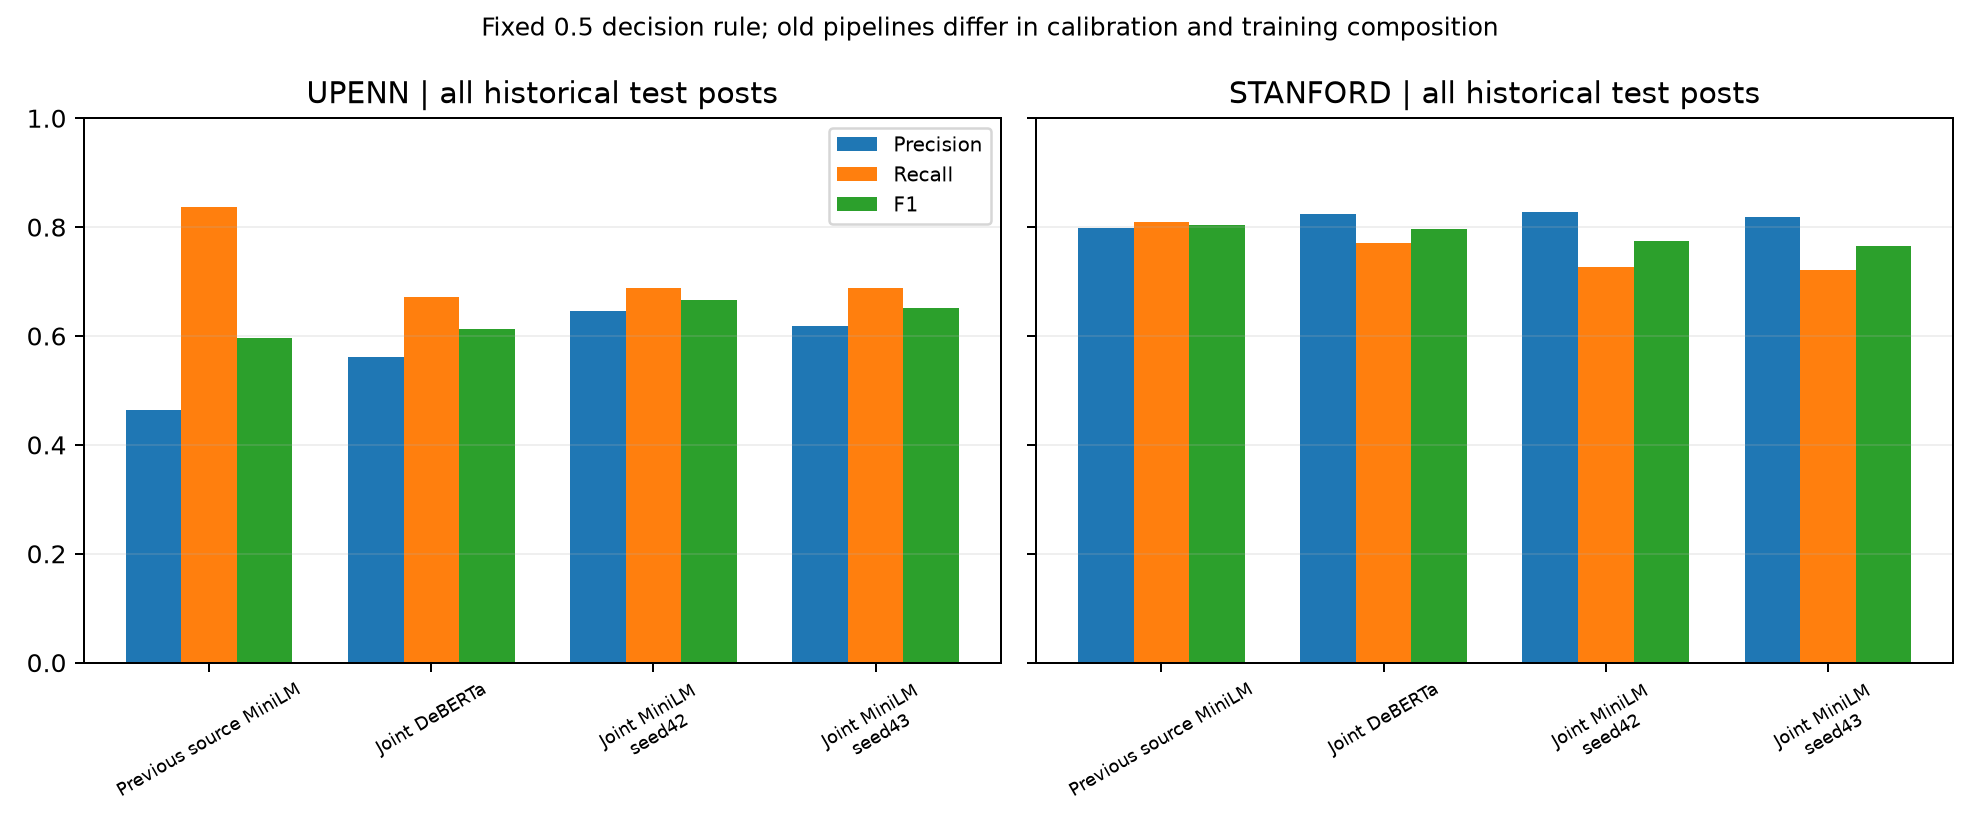

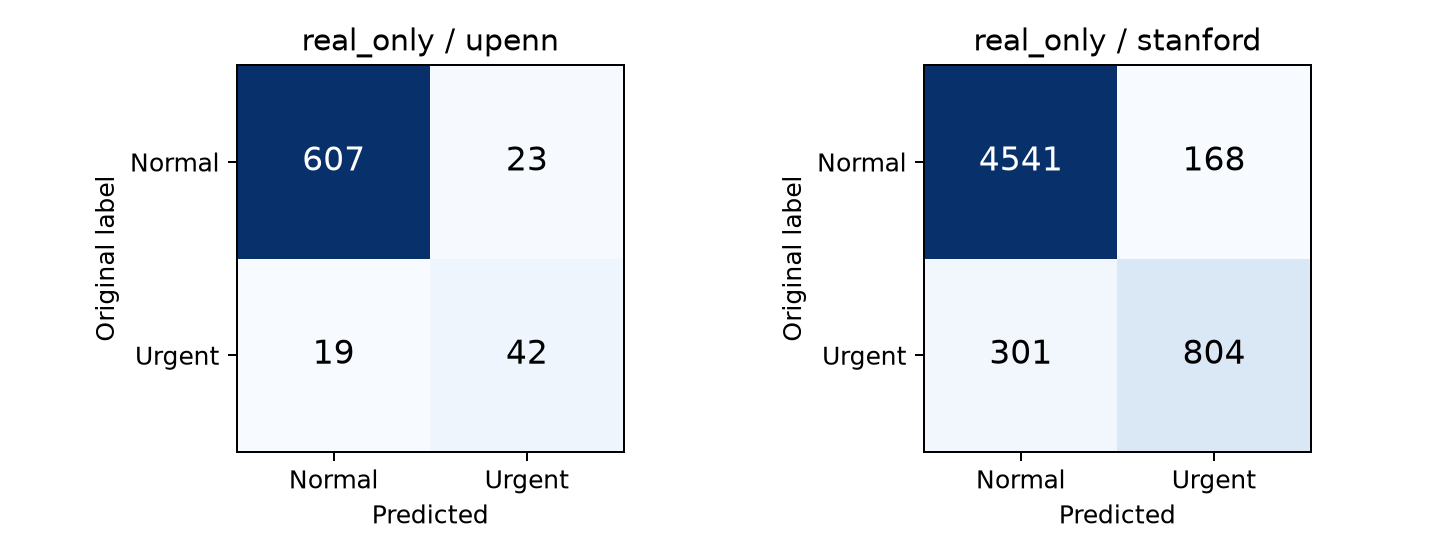

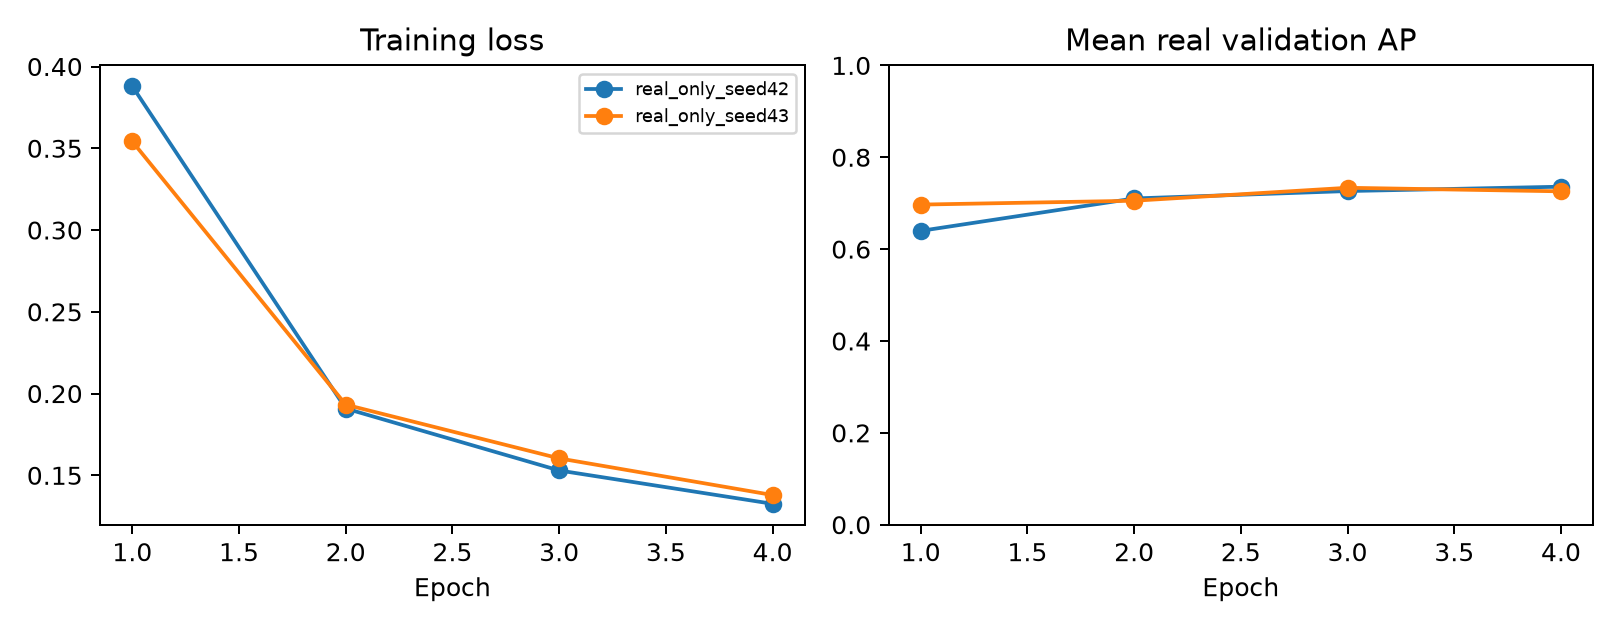

In [19]:
summary=json.loads((BASE/'control_summary.json').read_text())
display(Markdown('| Run | Test | Precision | Recall | F1 | Accuracy | FP | FN |\n|---|---|---:|---:|---:|---:|---:|---:|\n'+'\n'.join(
    f"| {r['run']} | {r['test_source']} | {r['precision']:.4f} | {r['recall']:.4f} | {r['f1']:.4f} | {r['accuracy']:.4f} | {r['confusion_matrix'][0][1]} | {r['confusion_matrix'][1][0]} |"
    for r in summary['results'])))
for row in summary['results']:print(json.dumps(row,indent=2))
for name in ['best_minilm_metrics.png','best_minilm_confusion.png','best_minilm_learning.png']:
    display(Image(filename=str(PROJECT/'reports/figures'/name)))


## Two seeds, context states, review coverage and errors

Two seeds describe initialization variation; they are not a confidence interval or an external validation study.


In [20]:
seed_path=BASE/'control_two_seed_summary.json'
print(seed_path.read_text())
for name,context in summary['contexts'].items():
    print(name,'held-out synthetic challenge:',json.dumps(context['challenge'],indent=2))
    for row in context['submission_examples']:print(row['case_type'],row['text'],row['score'],row['action'])
for row in summary['results']:
    if row['test_source']!='custom_challenge':
        print(row['run'],row['test_source'],{k:row[k] for k in ['automatic_coverage','review_count','automatic_errors',
              'urgent_automatically_missed','urgent_requiring_review']})
print((BASE/'control_error_examples.json').read_text())
print('Verification:',summary['checks'])


{
  "real_only": {
    "upenn": {
      "precision": {
        "mean": 0.6319004524886878,
        "std_across_two_seeds": 0.014253393665158376,
        "values_by_seed": {
          "42": 0.6461538461538462,
          "43": 0.6176470588235294
        }
      },
      "recall": {
        "mean": 0.6885245901639344,
        "std_across_two_seeds": 0.0,
        "values_by_seed": {
          "42": 0.6885245901639344,
          "43": 0.6885245901639344
        }
      },
      "f1": {
        "mean": 0.6589147286821706,
        "std_across_two_seeds": 0.007751937984496082,
        "values_by_seed": {
          "42": 0.6666666666666666,
          "43": 0.6511627906976745
        }
      },
      "accuracy": {
        "mean": 0.9370477568740956,
        "std_across_two_seeds": 0.002170767004341545,
        "values_by_seed": {
          "42": 0.9392185238784371,
          "43": 0.934876989869754
        }
      }
    },
    "stanford": {
      "precision": {
        "mean": 0.8226244401304353

## Extra phrasing and context probes

Sixteen binary draft expectations and four ambiguous/out-of-scope probes. These are assistant-authored diagnostics, never used for training or selecting the model, and not independently reviewed gold.


In [21]:
run('check_final_behavior.py','--exported-only','--control-only')
print((BASE/'control_behavior_probe_results.json').read_text())


You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


[
  {
    "model_key": "joint__minilm_real_control",
    "correct_binary_probes": 14,
    "diagnostic_binary_count": 16,
    "binary_errors": [
      "quoted_problem",
      "still_waiting"
    ],
    "unlabelled_probes_automatically_classified": [
      "vague",
      "missing_reference",
      "outside_recipe"
    ]
  }
]


[
  {
    "model_key": "joint__minilm_real_control",
    "label_status": "assistant-authored draft expectations, not human-adjudicated gold",
    "diagnostic_binary_count": 16,
    "diagnostic_accuracy": 0.875,
    "diagnostic_f1": 0.8571428571428571,
    "confusion_matrix": [
      [
        8,
        1
      ],
      [
        1,
        6
      ]
    ],
    "correct_binary_probes": 14,
    "binary_errors": [
      "quoted_problem",
      "still_waiting"
    ],
    "unlabelled_probes_automatically_classified": [
      "vague",
      "missing_reference",
      "outside_recipe"
    ],
    "predictions": [
      {
        "id": "unresolved_upload",
        "expected_binary_priority": 1,
        "text": "My report is finished, but every upload attempt fails. It is due in an hour and I need assistance.",
        "expected_handling": "binary context diagnostic",
        "priority": 1,
        "score": 0.8594827039446526,
        "action": "PRIORITY"
      },
      {
        "id": "resolve

## Try any new English student post

The exported folder includes weights, tokenizer, calibration and standalone prediction code. Change TEXT_TO_PREDICT and rerun this cell.


In [22]:
TEXT_TO_PREDICT='I cannot submit my assignment and the deadline is tonight. Please help!'
ARM_TO_USE='real_only'
MODEL_FOLDER=PROJECT/'models/urgency_final_minilm_real_only_seed42'
subprocess.run([sys.executable,str(MODEL_FOLDER/'predict.py'),'--text',TEXT_TO_PREDICT],check=True)
print('Final model folder:',MODEL_FOLDER)


{
  "text": "I cannot submit my assignment and the deadline is tonight. Please help!",
  "score": 0.9388301679202745,
  "raw_score": 0.9859800934791565,
  "threshold": 0.5,
  "binary_priority": 1,
  "action": "PRIORITY",
  "domain": "mixed",
  "scope": "English student forum posts",
  "note": "An estimate, not a guarantee of correctness."
}


Final model folder: /Users/nhaterik/lastyear/machine/Project/models/urgency_final_minilm_real_only_seed42


## Download trained folders, datasets and all statistics

The archive retains synthetic provenance and split IDs. The web app remains in the main local Project.


In [23]:
from zipfile import ZipFile,ZIP_DEFLATED
archive=PROJECT/'best_minilm_model_and_statistics.zip'
with ZipFile(archive,'w',ZIP_DEFLATED) as z:
    folders=[PROJECT/'Datasets',BASE,*sorted((PROJECT/'models').glob('urgency_final_minilm_real_only_*'))]
    for folder in folders:
        for file in folder.rglob('*'):
            if file.is_file() and file.name!='best_state.pt':z.write(file,str(file.relative_to(PROJECT)))
    for file in (PROJECT/'reports/figures').glob('best_minilm_*.png'):z.write(file,str(file.relative_to(PROJECT)))
print('Download from Kaggle Output:',archive,'MB:',round(archive.stat().st_size/1e6,1))


Download from Kaggle Output: /Users/nhaterik/lastyear/machine/Project/best_minilm_model_and_statistics.zip MB: 187.9
